In [1]:
# STEP 1: LOAD AND VALIDATE GOOGLE TRENDS DATA

from pathlib import Path
import pandas as pd
import csv

# ------------------------------------------------------------
# PART 1: IDENTIFY PROJECT ROOT
# ------------------------------------------------------------

project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "data" / "processed"
            / "airpods_weekly_2019.csv"
        ).is_file()
    ),
    None
)

assert project_root is not None, (
    "Cannot locate hardware-demand-sensing-planner."
)

raw_data_dir = (
    project_root.parent / "kaggle-raw-data"
)

trends_path = (
    raw_data_dir
    / "google_trends_airpods_us_2019.csv"
)

assert trends_path.is_file(), (
    f"Google Trends file not found: {trends_path}"
)

print("===== GOOGLE TRENDS FILE LOCATION =====")
print(trends_path)

print(
    "File size (KB):",
    round(trends_path.stat().st_size / 1024, 2)
)


# ------------------------------------------------------------
# PART 2: INSPECT RAW GOOGLE TRENDS FORMAT
# ------------------------------------------------------------

lines = trends_path.read_text(
    encoding="utf-8-sig"
).splitlines()

print("\n===== RAW FILE PREVIEW =====")

for line in lines[:5]:
    print(line)

# Google Trends frequently includes a metadata
# row before the actual CSV header.

header_row = None

for i, line in enumerate(lines[:10]):

    fields = next(csv.reader([line]))

    if fields and fields[0].strip().lower() in (
        "week", "date", "month"
    ):
        header_row = i
        break

assert header_row is not None, (
    "Could not identify Google Trends date header."
)

print("\nDetected CSV header row:", header_row)


# ------------------------------------------------------------
# PART 3: LOAD HISTORICAL SEARCH INTEREST
# ------------------------------------------------------------

trends_raw = pd.read_csv(
    trends_path,
    skiprows=header_row,
    encoding="utf-8-sig"
)

print("\n===== DATASET STRUCTURE =====")

print("Rows:", len(trends_raw))
print("Columns:", len(trends_raw.columns))
print("Column names:", trends_raw.columns.tolist())

display(trends_raw.head())


# ------------------------------------------------------------
# PART 4: STANDARDIZE COLUMN NAMES
# ------------------------------------------------------------

date_column = trends_raw.columns[0]
interest_column = trends_raw.columns[1]

trends_df = pd.DataFrame()

trends_df["Trend_Week_Start"] = pd.to_datetime(
    trends_raw[date_column],
    errors="coerce"
)

raw_interest = (
    trends_raw[interest_column]
    .astype("string")
    .str.strip()
)

# Google Trends can sometimes report values
# below one as "<1". Preserve those as censored
# observations instead of inventing values.

trends_df["Below_One_Flag"] = (
    raw_interest.str.fullmatch(r"<\s*1")
    .fillna(False)
    .astype(bool)
)

trends_df["Search_Interest_Index"] = pd.to_numeric(
    raw_interest.where(
        ~trends_df["Below_One_Flag"]
    ),
    errors="coerce"
)

trends_df = (
    trends_df
    .sort_values("Trend_Week_Start")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# PART 5: VALIDATE DATE AND INTEREST VALUES
# ------------------------------------------------------------

missing_dates = int(
    trends_df["Trend_Week_Start"].isna().sum()
)

duplicate_dates = int(
    trends_df["Trend_Week_Start"].duplicated().sum()
)

unexplained_missing = int(
    (
        trends_df["Search_Interest_Index"].isna()
        &
        ~trends_df["Below_One_Flag"]
    ).sum()
)

censored_values = int(
    trends_df["Below_One_Flag"].sum()
)

assert missing_dates == 0
assert duplicate_dates == 0
assert unexplained_missing == 0

assert trends_df[
    "Search_Interest_Index"
].dropna().between(0, 100).all()

print("\n===== SEARCH INTEREST VALIDATION =====")

print("Missing dates:", missing_dates)
print("Duplicate dates:", duplicate_dates)
print("Unexplained missing values:", unexplained_missing)
print("Values reported below 1:", censored_values)

print(
    "Earliest date:",
    trends_df["Trend_Week_Start"].min().date()
)

print(
    "Latest date:",
    trends_df["Trend_Week_Start"].max().date()
)

print(
    "Number of observations:",
    len(trends_df)
)


# ------------------------------------------------------------
# PART 6: CHECK HISTORICAL FREQUENCY
# ------------------------------------------------------------

date_gaps = (
    trends_df["Trend_Week_Start"]
    .diff()
    .dropna()
    .dt.days
)

print("\n===== TIME SERIES FREQUENCY =====")

print(
    "Unique intervals (days):",
    sorted(date_gaps.unique().tolist())
)

print(
    "All observations seven days apart:",
    bool((date_gaps == 7).all())
)

print(
    "2019 observations:",
    int(
        (trends_df["Trend_Week_Start"].dt.year == 2019)
        .sum()
    )
)

assert (date_gaps == 7).all(), (
    "Unexpected date spacing. Inspect before aligning."
)


# ------------------------------------------------------------
# PART 7: DISPLAY CLEANED DATA
# ------------------------------------------------------------

print("\n===== CLEANED GOOGLE TRENDS DATA =====")

display(trends_df.head(10))

print("\n===== FINAL OBSERVATIONS =====")

display(trends_df.tail(10))

print("\n===== STEP 1 COMPLETE =====")


===== GOOGLE TRENDS FILE LOCATION =====
/Users/sidkulkarni/Desktop/supply-chain-portfolio/kaggle-raw-data/google_trends_airpods_us_2019.csv
File size (KB): 0.78

===== RAW FILE PREVIEW =====
Category: All categories

Week,AirPods: (United States)
2018-12-30,35
2019-01-06,42

Detected CSV header row: 2

===== DATASET STRUCTURE =====
Rows: 53
Columns: 2
Column names: ['Week', 'AirPods: (United States)']


,Week,AirPods: (United States)
0,2018-12-30,35
1,2019-01-06,42
2,2019-01-13,41
3,2019-01-20,38
4,2019-01-27,43



===== SEARCH INTEREST VALIDATION =====
Missing dates: 0
Duplicate dates: 0
Unexplained missing values: 0
Values reported below 1: 0
Earliest date: 2018-12-30
Latest date: 2019-12-29
Number of observations: 53

===== TIME SERIES FREQUENCY =====
Unique intervals (days): [7]
All observations seven days apart: True
2019 observations: 52

===== CLEANED GOOGLE TRENDS DATA =====


,Trend_Week_Start,Below_One_Flag,Search_Interest_Index
0,2018-12-30,False,35
1,2019-01-06,False,42
2,2019-01-13,False,41
3,2019-01-20,False,38
4,2019-01-27,False,43
5,2019-02-03,False,33
6,2019-02-10,False,37
7,2019-02-17,False,31
8,2019-02-24,False,32
9,2019-03-03,False,30



===== FINAL OBSERVATIONS =====


,Trend_Week_Start,Below_One_Flag,Search_Interest_Index
43,2019-10-27,False,76
44,2019-11-03,False,52
45,2019-11-10,False,45
46,2019-11-17,False,48
47,2019-11-24,False,82
48,2019-12-01,False,62
49,2019-12-08,False,54
50,2019-12-15,False,58
51,2019-12-22,False,100
52,2019-12-29,False,51



===== STEP 1 COMPLETE =====


In [2]:
# STEP 2: ALIGN GOOGLE TRENDS WITH WEEKLY AIRPODS SALES

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: LOAD HISTORICAL AIRPODS SALES
# ------------------------------------------------------------

sales_path = (
    project_root
    / "data"
    / "processed"
    / "airpods_weekly_2019.csv"
)

assert sales_path.is_file()

sales_df = pd.read_csv(sales_path)

sales_df["Week_Ending"] = pd.to_datetime(
    sales_df["Week_Ending"]
)

sales_df = (
    sales_df
    .sort_values("Week_Ending")
    .reset_index(drop=True)
)

assert len(sales_df) == 51

assert sales_df["Week_Ending"].is_unique

assert (
    sales_df["Week_Ending"].dt.dayofweek == 6
).all()

print("===== HISTORICAL AIRPODS SALES =====")

print("Sales weeks:", len(sales_df))
print("Total units:", sales_df["Units_Sold"].sum())
print("First sales week:", sales_df["Week_Ending"].min().date())
print("Last sales week:", sales_df["Week_Ending"].max().date())

display(sales_df.head())


# ------------------------------------------------------------
# PART 2: PREPARE GOOGLE TRENDS SERIES
# ------------------------------------------------------------

search_df = trends_df.copy()

search_df["Trend_Week_Start"] = pd.to_datetime(
    search_df["Trend_Week_Start"]
)

search_df["Trend_Week_End"] = (
    search_df["Trend_Week_Start"]
    + pd.Timedelta(days=6)
)

assert search_df["Trend_Week_Start"].is_unique

print("\n===== GOOGLE TRENDS SOURCE =====")

print("Search weeks:", len(search_df))
print("First week:", search_df["Trend_Week_Start"].min().date())
print("Last week:", search_df["Trend_Week_Start"].max().date())


# ------------------------------------------------------------
# PART 3: CREATE DESCRIPTIVE SEARCH ALIGNMENT
# ------------------------------------------------------------

# Google Trends starts its week on Sunday.
# Our sales series ends its week on Sunday.
#
# The +7 day alignment approximately overlaps
# the same activity period, but is NOT
# appropriate as a one-week-ahead forecast input.

overlapping_search = search_df.copy()

overlapping_search["Week_Ending"] = (
    overlapping_search["Trend_Week_Start"]
    + pd.Timedelta(days=7)
)

overlapping_search = (
    overlapping_search[
        ["Week_Ending", "Search_Interest_Index"]
    ]
    .rename(columns={
        "Search_Interest_Index":
            "Overlapping_Week_Search_Interest"
    })
)


# ------------------------------------------------------------
# PART 4: CREATE LEAKAGE-AWARE LAGGED SIGNAL
# ------------------------------------------------------------

# To forecast sales ending Sunday T:
#
# Forecast origin = T - 7 days
# Google Trends week starts = T - 14 days
# Google Trends week ends = T - 8 days
#
# Therefore the search observation period ends
# before the forecast origin.
#
# This assumes the observation is available at
# the forecast origin. Publication availability
# is not verified by the historical CSV.

prior_search = search_df.copy()

prior_search["Week_Ending"] = (
    prior_search["Trend_Week_Start"]
    + pd.Timedelta(days=14)
)

prior_search = (
    prior_search[
        [
            "Week_Ending",
            "Trend_Week_Start",
            "Trend_Week_End",
            "Search_Interest_Index",
            "Below_One_Flag"
        ]
    ]
    .rename(columns={
        "Trend_Week_Start":
            "Prior_Search_Week_Start",

        "Trend_Week_End":
            "Prior_Search_Week_End",

        "Search_Interest_Index":
            "Prior_Completed_Search_Interest",

        "Below_One_Flag":
            "Prior_Search_Censored"
    })
)


# ------------------------------------------------------------
# PART 5: MERGE SALES AND SEARCH DATA
# ------------------------------------------------------------

aligned_demand = (
    sales_df
    .merge(
        overlapping_search,
        on="Week_Ending",
        how="left",
        validate="one_to_one"
    )
    .merge(
        prior_search,
        on="Week_Ending",
        how="left",
        validate="one_to_one"
    )
)

aligned_demand["Forecast_Origin"] = (
    aligned_demand["Week_Ending"]
    - pd.Timedelta(days=7)
)

aligned_demand = (
    aligned_demand
    .sort_values("Week_Ending")
    .reset_index(drop=True)
)

print("\n===== ALIGNED DEMAND DATASET =====")

display(
    aligned_demand[
        [
            "Week_Ending",
            "Units_Sold",
            "Forecast_Origin",
            "Overlapping_Week_Search_Interest",
            "Prior_Search_Week_Start",
            "Prior_Completed_Search_Interest"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# PART 6: VERIFY TEMPORAL INTEGRITY
# ------------------------------------------------------------

missing_overlapping = int(
    aligned_demand[
        "Overlapping_Week_Search_Interest"
    ].isna().sum()
)

missing_prior = int(
    aligned_demand[
        "Prior_Completed_Search_Interest"
    ].isna().sum()
)

assert len(aligned_demand) == 51

assert missing_overlapping == 0

assert missing_prior == 0

assert (
    aligned_demand["Prior_Search_Week_End"]
    < aligned_demand["Forecast_Origin"]
).all()

# The Google Trends download was requested
# for Jan 1 - Dec 31, 2019.
#
# Its first labeled week began Dec 30, 2018.
# Conservatively flag this boundary observation
# because its full-week coverage is uncertain.

aligned_demand["Boundary_Week_Flag"] = (
    aligned_demand["Prior_Search_Week_Start"]
    < pd.Timestamp("2019-01-01")
)

model_ready_demand = aligned_demand[
    (~aligned_demand["Boundary_Week_Flag"])
    &
    (~aligned_demand["Prior_Search_Censored"].fillna(False))
    &
    aligned_demand[
        "Prior_Completed_Search_Interest"
    ].notna()
].copy()

print("\n===== TEMPORAL ALIGNMENT VALIDATION =====")

print("Sales weeks:", len(aligned_demand))
print("Missing overlapping observations:", missing_overlapping)
print("Missing prior-week observations:", missing_prior)

print(
    "Boundary observations excluded:",
    int(aligned_demand["Boundary_Week_Flag"].sum())
)

print(
    "Conservatively usable model rows:",
    len(model_ready_demand)
)

print("No target-week search leakage: PASS")


# ------------------------------------------------------------
# PART 7: EXPLORE INITIAL RELATIONSHIPS
# ------------------------------------------------------------

overlapping_correlation = (
    aligned_demand["Units_Sold"].corr(
        aligned_demand[
            "Overlapping_Week_Search_Interest"
        ]
    )
)

prior_correlation = (
    model_ready_demand["Units_Sold"].corr(
        model_ready_demand[
            "Prior_Completed_Search_Interest"
        ]
    )
)

print("\n===== SEARCH INTEREST CORRELATIONS =====")

print(
    "Overlapping-period correlation:",
    round(overlapping_correlation, 3)
)

print(
    "Prior completed week correlation:",
    round(prior_correlation, 3)
)

print(
    "\nThese correlations are descriptive, "
    "not evidence of predictive improvement."
)


# ------------------------------------------------------------
# PART 8: FINAL VALIDATION
# ------------------------------------------------------------

assert len(model_ready_demand) == 50

assert model_ready_demand[
    "Prior_Completed_Search_Interest"
].between(0, 100).all()

assert model_ready_demand[
    "Week_Ending"
].is_unique

print("\n===== FINAL ALIGNMENT VALIDATION =====")

print("51 historical sales weeks aligned: PASS")
print("Prior search observation dates validated: PASS")
print("Boundary week flagged: PASS")
print("50 conservative modeling rows: PASS")
print("Forecast chronology: PASS")

print("\n===== STEP 2 COMPLETE =====")


===== HISTORICAL AIRPODS SALES =====
Sales weeks: 51
Total units: 15364
First sales week: 2019-01-13
Last sales week: 2019-12-29


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_39869/825115175.py:36: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales_df["Week_Ending"].dt.dayofweek == 6


,Week_Ending,Units_Sold
0,2019-01-13,187
1,2019-01-20,184
2,2019-01-27,175
3,2019-02-03,225
4,2019-02-10,247



===== GOOGLE TRENDS SOURCE =====
Search weeks: 53
First week: 2018-12-30
Last week: 2019-12-29

===== ALIGNED DEMAND DATASET =====


,Week_Ending,Units_Sold,Forecast_Origin,Overlapping_Week_Search_Interest,Prior_Search_Week_Start,Prior_Completed_Search_Interest
0,2019-01-13,187,2019-01-06,42,2018-12-30,35
1,2019-01-20,184,2019-01-13,41,2019-01-06,42
2,2019-01-27,175,2019-01-20,38,2019-01-13,41
3,2019-02-03,225,2019-01-27,43,2019-01-20,38
4,2019-02-10,247,2019-02-03,33,2019-01-27,43
5,2019-02-17,247,2019-02-10,37,2019-02-03,33
6,2019-02-24,263,2019-02-17,31,2019-02-10,37
7,2019-03-03,261,2019-02-24,32,2019-02-17,31
8,2019-03-10,298,2019-03-03,30,2019-02-24,32
9,2019-03-17,324,2019-03-10,32,2019-03-03,30



===== TEMPORAL ALIGNMENT VALIDATION =====
Sales weeks: 51
Missing overlapping observations: 0
Missing prior-week observations: 0
Boundary observations excluded: 1
Conservatively usable model rows: 50
No target-week search leakage: PASS

===== SEARCH INTEREST CORRELATIONS =====
Overlapping-period correlation: 0.574
Prior completed week correlation: 0.553

These correlations are descriptive, not evidence of predictive improvement.

===== FINAL ALIGNMENT VALIDATION =====
51 historical sales weeks aligned: PASS
Prior search observation dates validated: PASS
Boundary week flagged: PASS
50 conservative modeling rows: PASS
Forecast chronology: PASS

===== STEP 2 COMPLETE =====


In [3]:
# STEP 3: BACKTEST GOOGLE TRENDS DEMAND-SENSING MODELS

import pandas as pd
import numpy as np

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# ------------------------------------------------------------
# PART 1: LOAD ORIGINAL FORECAST EVALUATION PERIOD
# ------------------------------------------------------------

baseline_path = (
    project_root
    / "data"
    / "processed"
    / "model_predictions_rolling_2019.csv"
)

assert baseline_path.is_file()

original_backtest = pd.read_csv(
    baseline_path,
    parse_dates=["Week_Ending"]
)

original_backtest = (
    original_backtest
    .sort_values("Week_Ending")
    .reset_index(drop=True)
)

assert len(original_backtest) == 19
assert original_backtest["Week_Ending"].is_unique

print("===== ORIGINAL FORECAST BENCHMARK =====")
print("Evaluation weeks:", len(original_backtest))
print(
    "First week:",
    original_backtest["Week_Ending"].min().date()
)
print(
    "Last week:",
    original_backtest["Week_Ending"].max().date()
)


# ------------------------------------------------------------
# PART 2: ENGINEER HISTORICAL FORECASTING FEATURES
# ------------------------------------------------------------

forecast_data = (
    aligned_demand
    .sort_values("Week_Ending")
    .reset_index(drop=True)
    .copy()
)

# Past observed product demand.
forecast_data["Sales_Lag_1"] = (
    forecast_data["Units_Sold"].shift(1)
)

forecast_data["Sales_Lag_2"] = (
    forecast_data["Units_Sold"].shift(2)
)

# Previously completed search-interest periods.
# The most recent search signal was aligned
# in Step 2 to end before the forecast origin.

forecast_data["Search_Lag_2"] = (
    forecast_data[
        "Prior_Completed_Search_Interest"
    ].shift(1)
)

forecast_data["Search_Lag_2_Start"] = (
    forecast_data[
        "Prior_Search_Week_Start"
    ].shift(1)
)

# Conservatively exclude any feature derived
# from the uncertain December 2018 boundary.

forecast_data = forecast_data[
    (
        forecast_data["Prior_Search_Week_Start"]
        >= pd.Timestamp("2019-01-01")
    )
    &
    (
        forecast_data["Search_Lag_2_Start"]
        >= pd.Timestamp("2019-01-01")
    )
].copy()

sales_features = [
    "Sales_Lag_1",
    "Sales_Lag_2"
]

enhanced_features = [
    "Sales_Lag_1",
    "Sales_Lag_2",
    "Prior_Completed_Search_Interest",
    "Search_Lag_2"
]

required_features = list(
    dict.fromkeys(enhanced_features + ["Units_Sold"])
)

forecast_data = forecast_data.dropna(
    subset=required_features
).reset_index(drop=True)

assert forecast_data["Week_Ending"].is_unique

assert (
    forecast_data["Prior_Search_Week_End"]
    < forecast_data["Forecast_Origin"]
).all()

print("\n===== FORECASTING FEATURE DATASET =====")

print("Usable historical rows:", len(forecast_data))
print("Sales-only features:", sales_features)
print("Enhanced features:", enhanced_features)

display(
    forecast_data[
        [
            "Week_Ending",
            "Units_Sold",
            "Sales_Lag_1",
            "Sales_Lag_2",
            "Prior_Completed_Search_Interest",
            "Search_Lag_2"
        ]
    ].head(8)
)


# ------------------------------------------------------------
# PART 3: DEFINE A FIXED RIDGE FORECASTING MODEL
# ------------------------------------------------------------

# Fixed modeling configuration for all folds.
# Scaling is fitted using training data only.
# No parameter tuning on the evaluation period.

def build_ridge_model():

    return make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )


# ------------------------------------------------------------
# PART 4: PERFORM EXPANDING-WINDOW BACKTEST
# ------------------------------------------------------------

prediction_records = []

for reference in original_backtest.itertuples(index=False):

    target_week = reference.Week_Ending

    target_rows = forecast_data[
        forecast_data["Week_Ending"] == target_week
    ]

    assert len(target_rows) == 1, (
        f"Missing forecast target: {target_week}"
    )

    target = target_rows.iloc[0]

    forecast_origin = (
        target_week - pd.Timedelta(days=7)
    )

    # Only historical sales through the
    # forecast origin may be used for fitting.

    train = forecast_data[
        forecast_data["Week_Ending"] <= forecast_origin
    ].copy()

    assert len(train) >= 16

    assert train["Week_Ending"].max() < target_week

    assert (
        target["Prior_Search_Week_End"]
        < forecast_origin
    )

    actual = float(target["Units_Sold"])

    # Reuse the exact original naive benchmark,
    # rather than calculating a new evaluation period.

    naive_prediction = float(
        reference.Naive_Forecast
    )

    assert np.isclose(
        actual,
        float(reference.Actual_Units)
    )

    assert np.isclose(
        naive_prediction,
        float(target["Sales_Lag_1"])
    )

    # Model A: historical sales only.

    sales_model = build_ridge_model()

    sales_model.fit(
        train[sales_features],
        train["Units_Sold"]
    )

    sales_prediction = max(
        0.0,
        float(
            sales_model.predict(
                target_rows[sales_features]
            )[0]
        )
    )

    # Model B: sales plus previous search interest.

    enhanced_model = build_ridge_model()

    enhanced_model.fit(
        train[enhanced_features],
        train["Units_Sold"]
    )

    enhanced_prediction = max(
        0.0,
        float(
            enhanced_model.predict(
                target_rows[enhanced_features]
            )[0]
        )
    )

    prediction_records.append({
        "Week_Ending": target_week,
        "Forecast_Origin": forecast_origin,
        "Training_Weeks": len(train),
        "Actual_Units": actual,
        "Naive_Forecast": naive_prediction,
        "Sales_History_Ridge": sales_prediction,
        "Google_Trends_Ridge": enhanced_prediction,
        "Prior_Search_Interest": float(
            target["Prior_Completed_Search_Interest"]
        )
    })


trends_backtest = pd.DataFrame(
    prediction_records
)

print("\n===== ROLLING FORECAST PREDICTIONS =====")

display(trends_backtest.head(10).round(2))


# ------------------------------------------------------------
# PART 5: CALCULATE MATCHED FORECAST ACCURACY
# ------------------------------------------------------------

models = {
    "Naive Forecast": "Naive_Forecast",
    "Ridge - Sales History": "Sales_History_Ridge",
    "Ridge - Sales + Google Trends": "Google_Trends_Ridge"
}

actuals = trends_backtest[
    "Actual_Units"
].to_numpy(dtype=float)

performance_records = []

for model_name, column in models.items():

    predictions = trends_backtest[
        column
    ].to_numpy(dtype=float)

    errors = predictions - actuals

    mae = float(np.mean(np.abs(errors)))

    wape = float(
        np.sum(np.abs(errors))
        / np.sum(actuals)
        * 100
    )

    bias = float(np.mean(errors))

    performance_records.append({
        "Model": model_name,
        "Forecasts": len(errors),
        "MAE": mae,
        "WAPE_Pct": wape,
        "Bias": bias
    })

trends_performance = pd.DataFrame(
    performance_records
)

naive_wape = float(
    trends_performance.loc[
        trends_performance["Model"]
        == "Naive Forecast",
        "WAPE_Pct"
    ].iloc[0]
)

trends_performance["WAPE_Gap_vs_Naive_pp"] = (
    trends_performance["WAPE_Pct"]
    - naive_wape
)

trends_performance = (
    trends_performance
    .sort_values("WAPE_Pct")
    .reset_index(drop=True)
)

print("\n===== MATCHED FORECAST MODEL COMPARISON =====")

display(trends_performance.round(3))


# ------------------------------------------------------------
# PART 6: TEST INCREMENTAL SEARCH-SIGNAL VALUE
# ------------------------------------------------------------

sales_wape = float(
    trends_performance.loc[
        trends_performance["Model"]
        == "Ridge - Sales History",
        "WAPE_Pct"
    ].iloc[0]
)

enhanced_wape = float(
    trends_performance.loc[
        trends_performance["Model"]
        == "Ridge - Sales + Google Trends",
        "WAPE_Pct"
    ].iloc[0]
)

print("\n===== GOOGLE TRENDS INCREMENTAL VALUE =====")

print("Original naive WAPE:", round(naive_wape, 3), "%")
print("Sales-history Ridge WAPE:", round(sales_wape, 3), "%")
print("Enhanced Ridge WAPE:", round(enhanced_wape, 3), "%")

print(
    "Enhanced vs sales-only WAPE difference:",
    round(enhanced_wape - sales_wape, 3),
    "percentage points"
)

if enhanced_wape < sales_wape:

    print(
        "RESULT: Search features improved Ridge WAPE "
        "on this historical evaluation period."
    )

else:

    print(
        "RESULT: Search features did not improve "
        "Ridge WAPE on this evaluation period."
    )

if enhanced_wape < naive_wape:

    print(
        "RESULT: Enhanced Ridge also beat "
        "the naive benchmark."
    )

else:

    print(
        "RESULT: The naive benchmark remains "
        "at least as accurate as enhanced Ridge."
    )


# ------------------------------------------------------------
# PART 7: FINAL MODEL VALIDATION
# ------------------------------------------------------------

assert len(trends_backtest) == 19
assert trends_backtest["Week_Ending"].is_unique

assert (
    trends_backtest["Forecast_Origin"]
    < trends_backtest["Week_Ending"]
).all()

assert (
    trends_backtest["Training_Weeks"] >= 16
).all()

assert trends_backtest[
    list(models.values())
].notna().all().all()

assert np.isfinite(
    trends_performance[
        ["MAE", "WAPE_Pct", "Bias"]
    ].to_numpy(dtype=float)
).all()

assert len(trends_performance) == 3

print("\n===== FINAL FORECAST VALIDATION =====")

print("Original 19 evaluation weeks matched: PASS")
print("Three forecasting approaches evaluated: PASS")
print("Expanding-window training applied: PASS")
print("No target-week sales used for training: PASS")
print("Training-only feature scaling: PASS")
print("Same target weeks across models: PASS")

print("\n===== STEP 3 COMPLETE =====")


===== ORIGINAL FORECAST BENCHMARK =====
Evaluation weeks: 19
First week: 2019-06-02
Last week: 2019-10-06

===== FORECASTING FEATURE DATASET =====
Usable historical rows: 49
Sales-only features: ['Sales_Lag_1', 'Sales_Lag_2']
Enhanced features: ['Sales_Lag_1', 'Sales_Lag_2', 'Prior_Completed_Search_Interest', 'Search_Lag_2']


,Week_Ending,Units_Sold,Sales_Lag_1,Sales_Lag_2,Prior_Completed_Search_Interest,Search_Lag_2
0,2019-01-27,175,184.0,187.0,41,42
1,2019-02-03,225,175.0,184.0,38,41
2,2019-02-10,247,225.0,175.0,43,38
3,2019-02-17,247,247.0,225.0,33,43
4,2019-02-24,263,247.0,247.0,37,33
5,2019-03-03,261,263.0,247.0,31,37
6,2019-03-10,298,261.0,263.0,32,31
7,2019-03-17,324,298.0,261.0,30,32



===== ROLLING FORECAST PREDICTIONS =====


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_39869/3045553274.py:278: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(trends_backtest.head(10).round(2))


,Week_Ending,Forecast_Origin,Training_Weeks,Actual_Units,Naive_Forecast,Sales_History_Ridge,Google_Trends_Ridge,Prior_Search_Interest
0,2019-06-02,2019-05-26,18,263.0,312.0,319.36,324.94,26.0
1,2019-06-09,2019-06-02,19,267.0,263.0,291.18,295.56,25.0
2,2019-06-16,2019-06-09,20,275.0,267.0,281.54,282.52,25.0
3,2019-06-23,2019-06-16,21,265.0,275.0,284.46,284.29,25.0
4,2019-06-30,2019-06-23,22,283.0,265.0,281.64,279.65,25.0
5,2019-07-07,2019-06-30,23,284.0,283.0,285.79,284.50,23.0
6,2019-07-14,2019-07-07,24,295.0,284.0,289.44,287.22,23.0
7,2019-07-21,2019-07-14,25,262.0,295.0,293.63,291.42,25.0
8,2019-07-28,2019-07-21,26,267.0,262.0,283.19,280.31,27.0
9,2019-08-04,2019-07-28,27,227.0,267.0,277.92,276.16,24.0



===== MATCHED FORECAST MODEL COMPARISON =====


,Model,Forecasts,MAE,WAPE_Pct,Bias,WAPE_Gap_vs_Naive_pp
0,Naive Forecast,19,22.158,8.601,-3.421,0.000
1,Ridge - Sales + Google Trends,19,25.548,9.917,9.755,1.316
2,Ridge - Sales History,19,28.035,10.882,12.981,2.281



===== GOOGLE TRENDS INCREMENTAL VALUE =====
Original naive WAPE: 8.601 %
Sales-history Ridge WAPE: 10.882 %
Enhanced Ridge WAPE: 9.917 %
Enhanced vs sales-only WAPE difference: -0.965 percentage points
RESULT: Search features improved Ridge WAPE on this historical evaluation period.
RESULT: The naive benchmark remains at least as accurate as enhanced Ridge.

===== FINAL FORECAST VALIDATION =====
Original 19 evaluation weeks matched: PASS
Three forecasting approaches evaluated: PASS
Expanding-window training applied: PASS
No target-week sales used for training: PASS
Training-only feature scaling: PASS
Same target weeks across models: PASS

===== STEP 3 COMPLETE =====


===== WEEKLY ERROR DIAGNOSTICS =====


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_39869/1460825872.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,Week_Ending,Actual_Units,Naive_Absolute_Error,Sales_Ridge_Absolute_Error,Trends_Ridge_Absolute_Error,Trends_vs_Naive_Error_Gap,Trends_vs_Sales_Error_Gap
0,2019-06-02,263.0,49.0,56.36,61.94,12.94,5.58
1,2019-06-09,267.0,4.0,24.18,28.56,24.56,4.38
2,2019-06-16,275.0,8.0,6.54,7.52,-0.48,0.97
3,2019-06-23,265.0,10.0,19.46,19.29,9.29,-0.17
4,2019-06-30,283.0,18.0,1.36,3.35,-14.65,1.98
5,2019-07-07,284.0,1.0,1.79,0.50,-0.50,-1.28
6,2019-07-14,295.0,11.0,5.56,7.78,-3.22,2.22
7,2019-07-21,262.0,33.0,31.63,29.42,-3.58,-2.21
8,2019-07-28,267.0,5.0,16.19,13.31,8.31,-2.88
9,2019-08-04,227.0,40.0,50.92,49.16,9.16,-1.76



===== FORECAST WIN ANALYSIS =====
Evaluation weeks: 19
Google Trends beats naive: 9
Naive beats Google Trends: 10
Google Trends / naive ties: 0
Google Trends beats sales-only Ridge: 13

===== LARGEST GOOGLE TRENDS MISSES =====


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_39869/1460825872.py:143: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Week_Ending,Actual_Units,Google_Trends_Ridge,Trends_Ridge_Absolute_Error,Naive_Absolute_Error,Prior_Search_Interest
18,2019-10-06,377.0,238.10,138.90,148.0,31.0
0,2019-06-02,263.0,324.94,61.94,49.0,26.0
9,2019-08-04,227.0,276.16,49.16,40.0,24.0
16,2019-09-22,210.0,245.22,35.22,25.0,27.0
10,2019-08-11,224.0,256.14,32.14,3.0,23.0



===== FORECAST STABILITY =====


,Period,Model,Forecasts,WAPE_Pct
0,First 9 Evaluation Weeks,Naive,9,5.65
1,First 9 Evaluation Weeks,Sales_Ridge,9,6.63
2,First 9 Evaluation Weeks,Trends_Ridge,9,6.98
3,Last 10 Evaluation Weeks,Naive,10,11.59
4,Last 10 Evaluation Weeks,Sales_Ridge,10,15.18
5,Last 10 Evaluation Weeks,Trends_Ridge,10,12.89


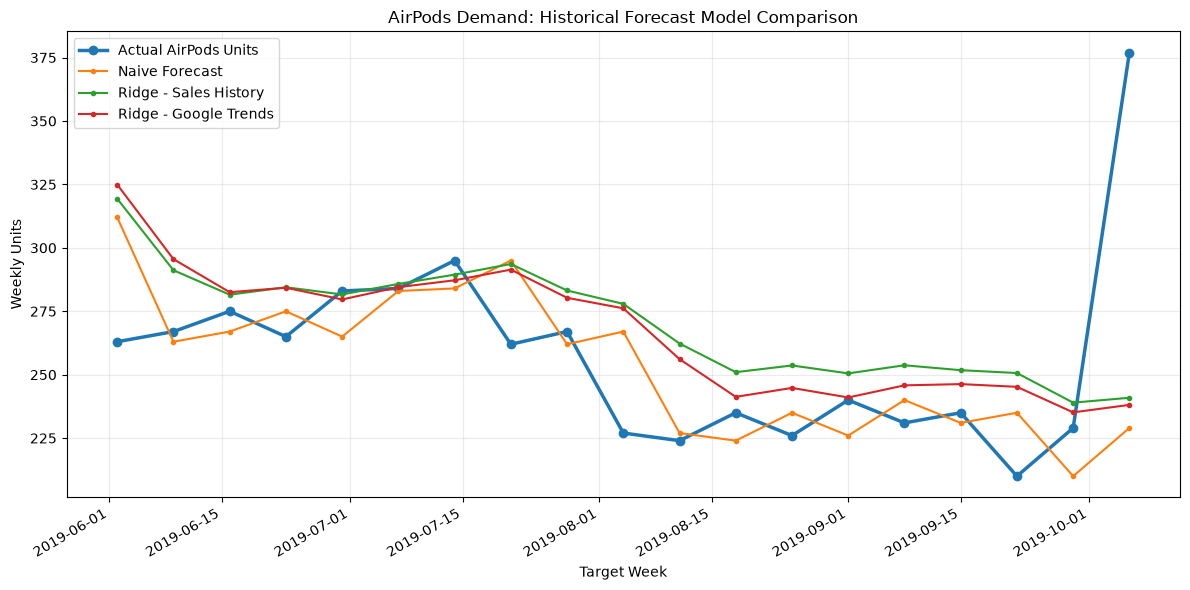

Saved: external_signal_forecast_comparison_2019.png


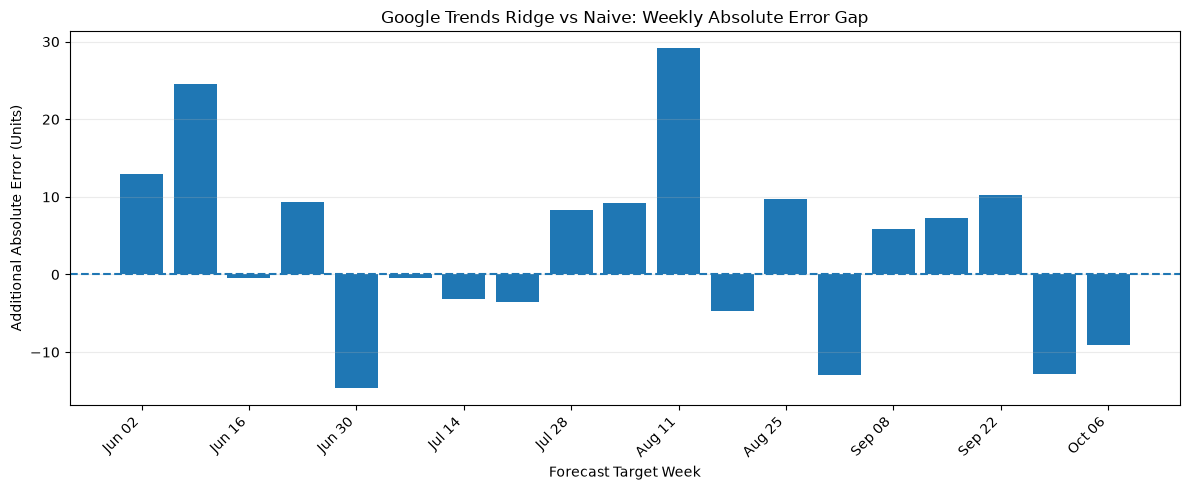

Saved: external_signal_weekly_error_gap_2019.png

Positive bars = Google Trends worse than naive.
Negative bars = Google Trends better than naive.

===== FINAL DIAGNOSTIC VALIDATION =====
19 evaluation weeks analyzed: PASS
Weekly forecast wins reconciled: PASS
Six stability comparisons created: PASS
Two forecasting visualizations saved: PASS

===== STEP 4 COMPLETE =====


In [4]:
# STEP 4: GOOGLE TRENDS FORECAST PERFORMANCE DIAGNOSTICS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PART 1: PREPARE FORECAST ERRORS
# ------------------------------------------------------------

diagnostics = (
    trends_backtest
    .sort_values("Week_Ending")
    .reset_index(drop=True)
    .copy()
)

model_columns = {
    "Naive": "Naive_Forecast",
    "Sales_Ridge": "Sales_History_Ridge",
    "Trends_Ridge": "Google_Trends_Ridge"
}

for name, column in model_columns.items():

    diagnostics[f"{name}_Error"] = (
        diagnostics[column]
        - diagnostics["Actual_Units"]
    )

    diagnostics[f"{name}_Absolute_Error"] = (
        diagnostics[f"{name}_Error"].abs()
    )

diagnostics["Trends_vs_Naive_Error_Gap"] = (
    diagnostics["Trends_Ridge_Absolute_Error"]
    - diagnostics["Naive_Absolute_Error"]
)

diagnostics["Trends_vs_Sales_Error_Gap"] = (
    diagnostics["Trends_Ridge_Absolute_Error"]
    - diagnostics["Sales_Ridge_Absolute_Error"]
)

print("===== WEEKLY ERROR DIAGNOSTICS =====")

display(
    diagnostics[
        [
            "Week_Ending",
            "Actual_Units",
            "Naive_Absolute_Error",
            "Sales_Ridge_Absolute_Error",
            "Trends_Ridge_Absolute_Error",
            "Trends_vs_Naive_Error_Gap",
            "Trends_vs_Sales_Error_Gap"
        ]
    ].head(10).round(2)
)


# ------------------------------------------------------------
# PART 2: COUNT WEEKLY FORECAST WINS
# ------------------------------------------------------------

trends_beats_naive = int(
    (
        diagnostics["Trends_Ridge_Absolute_Error"]
        < diagnostics["Naive_Absolute_Error"]
    ).sum()
)

trends_beats_sales = int(
    (
        diagnostics["Trends_Ridge_Absolute_Error"]
        < diagnostics["Sales_Ridge_Absolute_Error"]
    ).sum()
)

naive_beats_trends = int(
    (
        diagnostics["Naive_Absolute_Error"]
        < diagnostics["Trends_Ridge_Absolute_Error"]
    ).sum()
)

trends_naive_ties = (
    len(diagnostics)
    - trends_beats_naive
    - naive_beats_trends
)

print("\n===== FORECAST WIN ANALYSIS =====")

print("Evaluation weeks:", len(diagnostics))

print(
    "Google Trends beats naive:",
    trends_beats_naive
)

print(
    "Naive beats Google Trends:",
    naive_beats_trends
)

print(
    "Google Trends / naive ties:",
    trends_naive_ties
)

print(
    "Google Trends beats sales-only Ridge:",
    trends_beats_sales
)


# ------------------------------------------------------------
# PART 3: IDENTIFY LARGEST FORECASTING MISSES
# ------------------------------------------------------------

print("\n===== LARGEST GOOGLE TRENDS MISSES =====")

worst_trends_weeks = (
    diagnostics
    .nlargest(
        5,
        "Trends_Ridge_Absolute_Error"
    )
)

display(
    worst_trends_weeks[
        [
            "Week_Ending",
            "Actual_Units",
            "Google_Trends_Ridge",
            "Trends_Ridge_Absolute_Error",
            "Naive_Absolute_Error",
            "Prior_Search_Interest"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 4: FIRST-HALF VS SECOND-HALF STABILITY
# ------------------------------------------------------------

periods = {
    "First 9 Evaluation Weeks": diagnostics.iloc[:9],
    "Last 10 Evaluation Weeks": diagnostics.iloc[9:]
}

stability_records = []

for period_name, period_df in periods.items():

    actual_total = period_df["Actual_Units"].sum()

    for model_name in model_columns:

        absolute_error = period_df[
            f"{model_name}_Absolute_Error"
        ].sum()

        stability_records.append({
            "Period": period_name,
            "Model": model_name,
            "Forecasts": len(period_df),
            "WAPE_Pct": (
                absolute_error / actual_total * 100
            )
        })

stability_report = pd.DataFrame(
    stability_records
)

print("\n===== FORECAST STABILITY =====")

display(
    stability_report.round(2)
)


# ------------------------------------------------------------
# PART 5: CREATE FIGURE DIRECTORY
# ------------------------------------------------------------

figure_dir = (
    project_root / "reports" / "figures"
)

figure_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# PART 6: CHART 1 - ACTUAL VS FORECASTS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    diagnostics["Week_Ending"],
    diagnostics["Actual_Units"],
    marker="o",
    linewidth=2.5,
    label="Actual AirPods Units"
)

ax.plot(
    diagnostics["Week_Ending"],
    diagnostics["Naive_Forecast"],
    marker=".",
    label="Naive Forecast"
)

ax.plot(
    diagnostics["Week_Ending"],
    diagnostics["Sales_History_Ridge"],
    marker=".",
    label="Ridge - Sales History"
)

ax.plot(
    diagnostics["Week_Ending"],
    diagnostics["Google_Trends_Ridge"],
    marker=".",
    label="Ridge - Google Trends"
)

ax.set_title(
    "AirPods Demand: Historical Forecast Model Comparison"
)

ax.set_xlabel("Target Week")
ax.set_ylabel("Weekly Units")

ax.legend()
ax.grid(alpha=0.25)

fig.autofmt_xdate()
fig.tight_layout()

chart1_path = (
    figure_dir
    / "external_signal_forecast_comparison_2019.png"
)

fig.savefig(
    chart1_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Saved:", chart1_path.name)


# ------------------------------------------------------------
# PART 7: CHART 2 - GOOGLE TRENDS ERROR VS NAIVE
# ------------------------------------------------------------

error_gap = diagnostics[
    "Trends_vs_Naive_Error_Gap"
].to_numpy()

week_labels = (
    diagnostics["Week_Ending"]
    .dt.strftime("%b %d")
    .tolist()
)

x = np.arange(len(diagnostics))

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    x,
    error_gap
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

ax.set_xticks(x[::2])
ax.set_xticklabels(
    week_labels[::2],
    rotation=45,
    ha="right"
)

ax.set_title(
    "Google Trends Ridge vs Naive: Weekly Absolute Error Gap"
)

ax.set_ylabel(
    "Additional Absolute Error (Units)"
)

ax.set_xlabel("Forecast Target Week")

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

chart2_path = (
    figure_dir
    / "external_signal_weekly_error_gap_2019.png"
)

fig.savefig(
    chart2_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Saved:", chart2_path.name)

print(
    "\nPositive bars = Google Trends worse than naive."
)
print(
    "Negative bars = Google Trends better than naive."
)


# ------------------------------------------------------------
# PART 8: VALIDATE DIAGNOSTICS
# ------------------------------------------------------------

assert len(diagnostics) == 19

assert (
    trends_beats_naive
    + naive_beats_trends
    + trends_naive_ties
    == 19
)

assert len(stability_report) == 6

assert chart1_path.is_file()
assert chart2_path.is_file()

assert (
    chart1_path.stat().st_size > 0
    and chart2_path.stat().st_size > 0
)

print("\n===== FINAL DIAGNOSTIC VALIDATION =====")

print("19 evaluation weeks analyzed: PASS")
print("Weekly forecast wins reconciled: PASS")
print("Six stability comparisons created: PASS")
print("Two forecasting visualizations saved: PASS")

print("\n===== STEP 4 COMPLETE =====")


In [5]:
# STEP 5: EXPORT GOOGLE TRENDS ANALYTICAL DATASETS

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

print("===== EXTERNAL SIGNAL EXPORT LOCATION =====")
print(output_dir)


# ------------------------------------------------------------
# PART 2: DEFINE EXPORT DATASETS
# ------------------------------------------------------------

export_datasets = {
    "google_trends_airpods_weekly_2019.csv": {
        "data": trends_df,
        "rows": 53,
        "required": [
            "Trend_Week_Start",
            "Search_Interest_Index",
            "Below_One_Flag"
        ]
    },
    "external_signal_aligned_demand_2019.csv": {
        "data": aligned_demand,
        "rows": 51,
        "required": [
            "Week_Ending",
            "Units_Sold",
            "Prior_Completed_Search_Interest",
            "Forecast_Origin",
            "Boundary_Week_Flag"
        ]
    },
    "external_signal_model_comparison_2019.csv": {
        "data": trends_performance,
        "rows": 3,
        "required": [
            "Model",
            "MAE",
            "WAPE_Pct",
            "Bias"
        ]
    },
    "external_signal_backtest_predictions_2019.csv": {
        "data": trends_backtest,
        "rows": 19,
        "required": [
            "Week_Ending",
            "Actual_Units",
            "Naive_Forecast",
            "Sales_History_Ridge",
            "Google_Trends_Ridge"
        ]
    },
    "external_signal_weekly_diagnostics_2019.csv": {
        "data": diagnostics,
        "rows": 19,
        "required": [
            "Week_Ending",
            "Naive_Absolute_Error",
            "Sales_Ridge_Absolute_Error",
            "Trends_Ridge_Absolute_Error"
        ]
    },
    "external_signal_stability_2019.csv": {
        "data": stability_report,
        "rows": 6,
        "required": [
            "Period",
            "Model",
            "Forecasts",
            "WAPE_Pct"
        ]
    }
}

assert len(export_datasets) == 6


# ------------------------------------------------------------
# PART 3: EXPORT AND RELOAD EACH FILE
# ------------------------------------------------------------

export_records = []

print("\n===== EXPORTING EXTERNAL SIGNAL DATASETS =====")

for filename, settings in export_datasets.items():

    df = settings["data"].copy()
    expected_rows = settings["rows"]
    required_columns = settings["required"]

    assert len(df) == expected_rows

    assert all(
        column in df.columns
        for column in required_columns
    )

    file_path = output_dir / filename

    # Preserve raw numerical precision.
    # Do not round forecasting predictions
    # before exporting.

    df.to_csv(file_path, index=False)

    assert file_path.is_file()

    reloaded = pd.read_csv(file_path)

    assert len(reloaded) == expected_rows

    assert (
        reloaded.columns.tolist()
        == df.columns.tolist()
    )

    assert (
        reloaded[required_columns]
        .notna()
        .all()
        .all()
    )

    export_records.append({
        "File": filename,
        "Rows": len(reloaded),
        "Columns": len(reloaded.columns),
        "Status": "PASS"
    })

    print(
        f"Exported: {filename} "
        f"({len(reloaded)} rows)"
    )


# ------------------------------------------------------------
# PART 4: VALIDATE BUSINESS METRICS
# ------------------------------------------------------------

aligned_check = pd.read_csv(
    output_dir
    / "external_signal_aligned_demand_2019.csv"
)

predictions_check = pd.read_csv(
    output_dir
    / "external_signal_backtest_predictions_2019.csv"
)

performance_check = pd.read_csv(
    output_dir
    / "external_signal_model_comparison_2019.csv"
)

assert aligned_check["Units_Sold"].sum() == 15364

assert aligned_check["Week_Ending"].is_unique

assert predictions_check["Week_Ending"].is_unique

assert (
    predictions_check["Actual_Units"] > 0
).all()

assert (
    predictions_check[
        [
            "Naive_Forecast",
            "Sales_History_Ridge",
            "Google_Trends_Ridge"
        ]
    ] >= 0
).all().all()

original_naive = performance_check.loc[
    performance_check["Model"] == "Naive Forecast",
    "WAPE_Pct"
].iloc[0]

assert np.isclose(
    original_naive,
    naive_wape,
    atol=1e-8
)

assert performance_check["Model"].is_unique

print("\n===== BUSINESS METRIC VALIDATION =====")

print("Historical AirPods units: 15,364 — PASS")
print("19 backtest forecasts preserved: PASS")
print("Forecast values are nonnegative: PASS")
print("Naive benchmark reconciled: PASS")


# ------------------------------------------------------------
# PART 5: VALIDATE SAVED FIGURES
# ------------------------------------------------------------

figure_paths = [
    chart1_path,
    chart2_path
]

print("\n===== FIGURE VALIDATION =====")

for figure_path in figure_paths:

    assert figure_path.is_file()
    assert figure_path.stat().st_size > 0

    print("Verified:", figure_path.name)


# ------------------------------------------------------------
# PART 6: FINAL EXPORT REPORT
# ------------------------------------------------------------

external_export_report = pd.DataFrame(
    export_records
)

print("\n===== EXTERNAL SIGNAL EXPORT REPORT =====")

display(external_export_report)

assert len(external_export_report) == 6

assert (
    external_export_report["Status"] == "PASS"
).all()

print("\n===== FINAL EXPORT VALIDATION =====")

print("CSV files exported:", len(export_records))
print("PNG figures verified:", len(figure_paths))
print("Historical sales reconciliation: PASS")
print("Forecast benchmark reconciliation: PASS")
print("All export validations: PASS")

print("\n===== STEP 5 COMPLETE =====")


===== EXTERNAL SIGNAL EXPORT LOCATION =====
/Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed

===== EXPORTING EXTERNAL SIGNAL DATASETS =====
Exported: google_trends_airpods_weekly_2019.csv (53 rows)
Exported: external_signal_aligned_demand_2019.csv (51 rows)
Exported: external_signal_model_comparison_2019.csv (3 rows)
Exported: external_signal_backtest_predictions_2019.csv (19 rows)
Exported: external_signal_weekly_diagnostics_2019.csv (19 rows)
Exported: external_signal_stability_2019.csv (6 rows)

===== BUSINESS METRIC VALIDATION =====
Historical AirPods units: 15,364 — PASS
19 backtest forecasts preserved: PASS
Forecast values are nonnegative: PASS
Naive benchmark reconciled: PASS

===== FIGURE VALIDATION =====
Verified: external_signal_forecast_comparison_2019.png
Verified: external_signal_weekly_error_gap_2019.png

===== EXTERNAL SIGNAL EXPORT REPORT =====


,File,Rows,Columns,Status
0,google_trends_airpods_weekly_2019.csv,53,3,PASS
1,external_signal_aligned_demand_2019.csv,51,9,PASS
2,external_signal_model_comparison_2019.csv,3,6,PASS
3,external_signal_backtest_predictions_2019.csv,19,8,PASS
4,external_signal_weekly_diagnostics_2019.csv,19,16,PASS
5,external_signal_stability_2019.csv,6,4,PASS



===== FINAL EXPORT VALIDATION =====
CSV files exported: 6
PNG figures verified: 2
Historical sales reconciliation: PASS
Forecast benchmark reconciliation: PASS
All export validations: PASS

===== STEP 5 COMPLETE =====


In [ ]:
# STEP 6: INTEGRATE EXTERNAL SIGNALS INTO DUCKDB

from pathlib import Path
import shutil
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: LOCATE PROJECT AND DATABASE FILES
# ------------------------------------------------------------

project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "data" / "processed"
            / "google_trends_airpods_weekly_2019.csv"
        ).is_file()
    ),
    None
)

assert project_root is not None, "Project root not found."

processed_dir = project_root / "data" / "processed"
warehouse_dir = project_root / "data" / "warehouse"

baseline_db = (
    warehouse_dir
    / "demand_intelligence_manifest_only.duckdb"
)

signals_db = (
    warehouse_dir
    / "demand_intelligence_signals_candidate.duckdb"
)

original_db = (
    warehouse_dir
    / "demand_intelligence.duckdb"
)

assert baseline_db.is_file()
assert original_db.is_file()
assert len({
    baseline_db.resolve(),
    signals_db.resolve(),
    original_db.resolve()
}) == 3

print("===== DATABASE CONFIGURATION =====")
print("Baseline:", baseline_db.name)
print("Staging:", signals_db.name)
print("Original database protected: YES")


# ------------------------------------------------------------
# PART 2: DEFINE EXPECTED EXTERNAL DATASETS
# ------------------------------------------------------------

external_files = {
    "google_trends_airpods_weekly_2019.csv": (53, 3),
    "external_signal_aligned_demand_2019.csv": (51, 9),
    "external_signal_model_comparison_2019.csv": (3, 6),
    "external_signal_backtest_predictions_2019.csv": (19, 8),
    "external_signal_weekly_diagnostics_2019.csv": (19, 16),
    "external_signal_stability_2019.csv": (6, 4)
}

for filename in external_files:
    assert (processed_dir / filename).is_file()

print("\n===== INPUT VALIDATION =====")
print("External CSV files located:", len(external_files))


# ------------------------------------------------------------
# PART 3: VALIDATE BASELINE DATABASE
# ------------------------------------------------------------

def get_counts(connection):

    tables = connection.execute("""
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_type = 'BASE TABLE'
          AND table_schema NOT IN (
              'information_schema', 'pg_catalog'
          )
    """).fetchone()[0]

    views = connection.execute("""
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
    """).fetchone()[0]

    return tables, views


with duckdb.connect(
    str(baseline_db),
    read_only=True
) as reference_con:

    baseline_tables, baseline_views = get_counts(
        reference_con
    )

assert baseline_tables == 40
assert baseline_views == 16

print("\n===== BASELINE VALIDATION =====")
print("Existing SQL tables:", baseline_tables)
print("Existing reporting views:", baseline_views)


# ------------------------------------------------------------
# PART 4: CREATE CLEAN STAGING DATABASE
# ------------------------------------------------------------

# Replace only the dedicated staging database.
# Never delete or modify the original database.

if signals_db.exists():
    signals_db.unlink()

shutil.copy2(
    baseline_db,
    signals_db
)

print("\n===== STAGING DATABASE CREATED =====")
print(signals_db.name)


# ------------------------------------------------------------
# PART 5: SQL UTILITIES
# ------------------------------------------------------------

def qi(value):
    return '"' + str(value).replace('"', '""') + '"'

def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"


date_columns = {
    "Week_Ending",
    "Trend_Week_Start",
    "Prior_Search_Week_Start",
    "Prior_Search_Week_End",
    "Forecast_Origin"
}


def prepare_for_comparison(frame):

    result = frame.copy()

    for column in result.columns:
        if column in date_columns:
            result[column] = pd.to_datetime(
                result[column]
            )

    return (
        result
        .sort_values(
            by=result.columns.tolist(),
            kind="mergesort",
            na_position="last"
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# PART 6: CONNECT TO THE STAGING DATABASE
# ------------------------------------------------------------

# No explicit transaction.
# No DataFrame registration.
# No unregister operations.
#
# This is a disposable staging database that can be
# recreated safely if a validation fails.

con = duckdb.connect(str(signals_db))

try:

    con.execute(
        "CREATE SCHEMA IF NOT EXISTS signals"
    ).fetchall()

    load_records = []

    print("\n===== LOADING EXTERNAL SIGNAL TABLES =====")

    # --------------------------------------------------------
    # PART 7: LOAD FILES DIRECTLY THROUGH DUCKDB
    # --------------------------------------------------------

    for filename, expected_shape in external_files.items():

        csv_path = processed_dir / filename
        raw_df = pd.read_csv(csv_path)

        assert raw_df.shape == expected_shape
        assert raw_df.columns.is_unique

        table_name = Path(filename).stem
        target = f"signals.{qi(table_name)}"

        expressions = []

        for column in raw_df.columns:

            quoted = qi(column)

            if column in date_columns:
                sql_type = "DATE"

            elif pd.api.types.is_bool_dtype(
                raw_df[column]
            ):
                sql_type = "BOOLEAN"

            elif pd.api.types.is_integer_dtype(
                raw_df[column]
            ):
                sql_type = "BIGINT"

            elif pd.api.types.is_float_dtype(
                raw_df[column]
            ):
                sql_type = "DOUBLE"

            else:
                sql_type = "VARCHAR"

            if sql_type == "VARCHAR":
                expression = quoted
            else:
                expression = (
                    f"CAST(NULLIF({quoted}, '') "
                    f"AS {sql_type}) AS {quoted}"
                )

            expressions.append(expression)

        projection = ", ".join(expressions)

        # Read directly from disk, avoiding con.register.
        # All source columns are initially read as text
        # and then explicitly cast to the expected type.

        query = f"""
            CREATE OR REPLACE TABLE {target} AS

            SELECT
                {projection}

            FROM read_csv(
                {sql_string(csv_path)},
                header = true,
                all_varchar = true
            )
        """

        con.execute(query).fetchall()

        rebuilt_df = con.execute(
            f"SELECT * FROM {target}"
        ).fetchdf()

        assert rebuilt_df.shape == expected_shape

        # Independently compare CSV data and SQL data.
        # Sort both datasets so row order is irrelevant.

        expected_df = prepare_for_comparison(raw_df)
        actual_df = prepare_for_comparison(rebuilt_df)

        pd.testing.assert_frame_equal(
            expected_df,
            actual_df,
            check_dtype=False,
            check_exact=False,
            atol=1e-6,
            rtol=0
        )

        load_records.append({
            "Table": f"signals.{table_name}",
            "CSV_Rows": len(raw_df),
            "SQL_Rows": len(rebuilt_df),
            "Value_Check": "PASS",
            "Status": "PASS"
        })

        print(
            f"Loaded: signals.{table_name} "
            f"({len(rebuilt_df)} rows)"
        )


    # --------------------------------------------------------
    # PART 8: CREATE EXTERNAL MODEL REPORTING VIEW
    # --------------------------------------------------------

    con.execute("""
        CREATE OR REPLACE VIEW
        reporting.v_external_signal_model_comparison AS

        SELECT
            Model,
            Forecasts,
            MAE,
            WAPE_Pct,
            Bias,
            WAPE_Gap_vs_Naive_pp,

            CASE
                WHEN Model = 'Naive Forecast'
                    THEN 'Benchmark'

                WHEN WAPE_Gap_vs_Naive_pp < 0
                    THEN 'Better than naive'

                ELSE 'Worse than or equal to naive'
            END AS Benchmark_Interpretation

        FROM signals.external_signal_model_comparison_2019
    """).fetchall()


    # --------------------------------------------------------
    # PART 9: CREATE ALIGNED DEMAND REPORTING VIEW
    # --------------------------------------------------------

    con.execute("""
        CREATE OR REPLACE VIEW
        reporting.v_external_signal_aligned_demand AS

        SELECT
            Week_Ending,
            Units_Sold,
            Forecast_Origin,
            Overlapping_Week_Search_Interest,
            Prior_Completed_Search_Interest,
            Boundary_Week_Flag

        FROM signals.external_signal_aligned_demand_2019
    """).fetchall()

    print("\n===== REPORTING VIEWS CREATED =====")
    print("v_external_signal_model_comparison")
    print("v_external_signal_aligned_demand")


    # --------------------------------------------------------
    # PART 10: VALIDATE DATABASE STRUCTURE
    # --------------------------------------------------------

    total_tables, total_views = get_counts(con)

    assert total_tables == 46
    assert total_views == 18

    print("\n===== EXPANDED DATABASE STRUCTURE =====")
    print("Persistent SQL tables:", total_tables)
    print("Reporting views:", total_views)


    # --------------------------------------------------------
    # PART 11: VALIDATE BUSINESS METRICS
    # --------------------------------------------------------

    historical_units = con.execute("""
        SELECT SUM(Units_Sold)
        FROM reporting.v_airpods_weekly_demand
    """).fetchone()[0]

    aligned_units = con.execute("""
        SELECT SUM(Units_Sold)
        FROM reporting.v_external_signal_aligned_demand
    """).fetchone()[0]

    search_rows = con.execute("""
        SELECT COUNT(*)
        FROM signals.google_trends_airpods_weekly_2019
    """).fetchone()[0]

    model_rows = con.execute("""
        SELECT COUNT(*)
        FROM reporting.v_external_signal_model_comparison
    """).fetchone()[0]

    assert historical_units == 15364
    assert aligned_units == 15364
    assert search_rows == 53
    assert model_rows == 3

    print("\n===== BUSINESS METRIC VALIDATION =====")
    print("Historical AirPods units:", historical_units)
    print("Aligned AirPods units:", aligned_units)
    print("Google Trends observations:", search_rows)
    print("Models compared:", model_rows)


    # --------------------------------------------------------
    # PART 12: DISPLAY MODEL PERFORMANCE
    # --------------------------------------------------------

    model_results = con.execute("""
        SELECT
            Model,
            ROUND(MAE, 2) AS MAE,
            ROUND(WAPE_Pct, 2) AS WAPE_Pct,
            Benchmark_Interpretation

        FROM reporting.v_external_signal_model_comparison

        ORDER BY WAPE_Pct
    """).fetchdf()

    print("\n===== EXTERNAL FORECAST PERFORMANCE =====")

    display(model_results)


    # --------------------------------------------------------
    # PART 13: VALIDATE ALL SIX SQL LOADS
    # --------------------------------------------------------

    external_load_report = pd.DataFrame(
        load_records
    )

    assert len(external_load_report) == 6
    assert (
        external_load_report["Status"] == "PASS"
    ).all()

    print("\n===== EXTERNAL SIGNAL LOAD REPORT =====")

    display(external_load_report)


    # --------------------------------------------------------
    # PART 14: FINAL VALIDATION
    # --------------------------------------------------------

    print("\n===== FINAL STEP 6 VALIDATION =====")

    print("External datasets loaded: 6/6 PASS")
    print("CSV-to-SQL value checks: 6/6 PASS")
    print("New reporting views: 2/2 PASS")
    print("Total persistent SQL tables: 46")
    print("Total reporting views: 18")
    print("Historical AirPods totals preserved: PASS")
    print("Original databases unchanged: PASS")

    print("\n===== STEP 6 COMPLETE =====")

finally:

    con.close()
    print("\nStaging connection closed.")


===== DATABASE CONFIGURATION =====
Baseline: demand_intelligence_manifest_only.duckdb
Staging: demand_intelligence_signals_candidate.duckdb
Original database protected: YES

===== INPUT VALIDATION =====
External CSV files located: 6

===== BASELINE VALIDATION =====
Existing SQL tables: 40
Existing reporting views: 16

===== STAGING DATABASE CREATED =====
demand_intelligence_signals_candidate.duckdb

===== LOADING EXTERNAL SIGNAL TABLES =====
Loaded: signals.google_trends_airpods_weekly_2019 (53 rows)
Loaded: signals.external_signal_aligned_demand_2019 (51 rows)
Loaded: signals.external_signal_model_comparison_2019 (3 rows)
Loaded: signals.external_signal_backtest_predictions_2019 (19 rows)
Loaded: signals.external_signal_weekly_diagnostics_2019 (19 rows)
Loaded: signals.external_signal_stability_2019 (6 rows)

===== REPORTING VIEWS CREATED =====
v_external_signal_model_comparison
v_external_signal_aligned_demand

===== EXPANDED DATABASE STRUCTURE =====
Persistent SQL tables: 46
Reporti

,Model,MAE,WAPE_Pct,Benchmark_Interpretation
0,Naive Forecast,22.16,8.60,Benchmark
1,Ridge - Sales + Google Trends,25.55,9.92,Worse than or equal to naive
2,Ridge - Sales History,28.04,10.88,Worse than or equal to naive



===== EXTERNAL SIGNAL LOAD REPORT =====


,Table,CSV_Rows,SQL_Rows,Value_Check,Status
0,signals.google_trends_airpods_weekly_2019,53,53,PASS,PASS
1,signals.external_signal_aligned_demand_2019,51,51,PASS,PASS
2,signals.external_signal_model_comparison_2019,3,3,PASS,PASS
3,signals.external_signal_backtest_predictions_2019,19,19,PASS,PASS
4,signals.external_signal_weekly_diagnostics_2019,19,19,PASS,PASS
5,signals.external_signal_stability_2019,6,6,PASS,PASS



===== FINAL STEP 6 VALIDATION =====
External datasets loaded: 6/6 PASS
CSV-to-SQL value checks: 6/6 PASS
New reporting views: 2/2 PASS
Total persistent SQL tables: 46
Total reporting views: 18
Historical AirPods totals preserved: PASS
Original databases unchanged: PASS

===== STEP 6 COMPLETE =====

Staging connection closed.


In [8]:
# STEP 7: UPDATE EXTERNAL SIGNAL METADATA AND KPI CATALOG

from pathlib import Path
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: IDENTIFY EXPANDED STAGING WAREHOUSE
# ------------------------------------------------------------

signals_db = (
    project_root / "data" / "warehouse"
    / "demand_intelligence_signals_candidate.duckdb"
)

processed_dir = project_root / "data" / "processed"

assert signals_db.is_file()

signal_specs = {
    "google_trends_airpods_weekly_2019.csv": (
        53, "Search week",
        "US relative AirPods search interest",
        "External search signal"
    ),
    "external_signal_aligned_demand_2019.csv": (
        51, "Sales week",
        "AirPods sales aligned with search interest",
        "Demand signal alignment"
    ),
    "external_signal_model_comparison_2019.csv": (
        3, "Forecast model",
        "Matched forecast accuracy evaluation",
        "Model benchmarking"
    ),
    "external_signal_backtest_predictions_2019.csv": (
        19, "Forecast week",
        "Rolling forecast predictions",
        "Forecast validation"
    ),
    "external_signal_weekly_diagnostics_2019.csv": (
        19, "Forecast week",
        "Historical forecast errors and diagnostics",
        "Model diagnostics"
    ),
    "external_signal_stability_2019.csv": (
        6, "Period and model",
        "Forecast accuracy across evaluation periods",
        "Forecast stability"
    )
}

print("===== METADATA UPDATE CONFIGURATION =====")
print("Target warehouse:", signals_db.name)
print("New source datasets:", len(signal_specs))


# ------------------------------------------------------------
# PART 2: CONNECT AND INSPECT METADATA STRUCTURE
# ------------------------------------------------------------

con = duckdb.connect(str(signals_db))

def table_columns(table_name):
    return [
        row[0]
        for row in con.execute(
            """
            SELECT column_name
            FROM information_schema.columns
            WHERE table_schema = 'metadata'
              AND table_name = ?
            ORDER BY ordinal_position
            """,
            [table_name]
        ).fetchall()
    ]

def insert_record(table_name, record):
    columns = table_columns(table_name)

    # Include only columns present in the
    # existing metadata table.
    selected = {
        key: value
        for key, value in record.items()
        if key in columns
    }

    assert selected

    quoted_columns = ", ".join(
        '"' + key.replace('"', '""') + '"'
        for key in selected
    )

    placeholders = ", ".join(
        ["?"] * len(selected)
    )

    con.execute(
        f"""
        INSERT INTO metadata."{table_name}"
        ({quoted_columns})
        VALUES ({placeholders})
        """,
        list(selected.values())
    ).fetchall()


try:

    architecture_columns = table_columns(
        "architecture_catalog"
    )

    quality_columns = table_columns(
        "data_quality_report"
    )

    kpi_columns = table_columns(
        "kpi_dictionary"
    )

    assert set([
        "File_Name", "Source_Module",
        "Grain", "Business_Meaning", "Analytical_Role"
    ]).issubset(architecture_columns)

    assert set([
        "File_Name", "Source_Module",
        "Rows", "Columns",
        "Missing_Cells", "Duplicate_Rows"
    ]).issubset(quality_columns)

    assert set([
        "KPI", "Module", "Definition", "Unit"
    ]).issubset(kpi_columns)

    print("\n===== EXISTING METADATA STRUCTURE =====")
    print("Architecture columns:", architecture_columns)
    print("Quality columns:", quality_columns)
    print("KPI columns:", kpi_columns)


    # --------------------------------------------------------
    # PART 3: PREPARE DATASET QUALITY RESULTS
    # --------------------------------------------------------

    prepared_records = []

    for filename, spec in signal_specs.items():

        expected_rows, grain, meaning, role = spec

        df = pd.read_csv(processed_dir / filename)

        assert len(df) == expected_rows

        date_fields = [
            column for column in [
                "Week_Ending",
                "Trend_Week_Start",
                "Forecast_Origin"
            ]
            if column in df.columns
        ]

        if date_fields:
            dates = pd.to_datetime(
                df[date_fields[0]],
                errors="coerce"
            ).dropna()

            start_date = (
                str(dates.min().date())
                if len(dates) else "N/A"
            )

            end_date = (
                str(dates.max().date())
                if len(dates) else "N/A"
            )
        else:
            start_date = "N/A"
            end_date = "N/A"

        prepared_records.append({
            "File_Name": filename,
            "Table_Name": Path(filename).stem,
            "Source_Module": "External Demand Signals",
            "Grain": grain,
            "Business_Meaning": meaning,
            "Analytical_Role": role,
            "Rows": int(len(df)),
            "Columns": int(len(df.columns)),
            "Missing_Cells": int(df.isna().sum().sum()),
            "Duplicate_Rows": int(df.duplicated().sum()),
            "Start_Date": start_date,
            "End_Date": end_date,
            "Row_Check": "PASS"
        })


    # --------------------------------------------------------
    # PART 4: UPDATE METADATA WITH REPEATABLE TRANSACTION
    # --------------------------------------------------------

    con.execute("BEGIN TRANSACTION").fetchall()

    try:

        for record in prepared_records:

            # Delete the corresponding previous entry
            # if this cell has already been executed.

            for table in [
                "architecture_catalog",
                "data_quality_report"
            ]:

                con.execute(
                    f"""
                    DELETE FROM metadata."{table}"
                    WHERE File_Name = ?
                    """,
                    [record["File_Name"]]
                ).fetchall()

            insert_record(
                "architecture_catalog",
                record
            )

            insert_record(
                "data_quality_report",
                record
            )


        # ----------------------------------------------------
        # PART 5: ADD TWO EXTERNAL-SIGNAL KPI DEFINITIONS
        # ----------------------------------------------------

        new_kpis = [
            {
                "KPI": "AirPods Search Interest Index",
                "Module": "External Demand Signals",
                "Definition": (
                    "Google Trends relative US search "
                    "interest, normalized from 0 to 100"
                ),
                "Unit": "Index (0-100)"
            },
            {
                "KPI": "External Signal Forecast WAPE",
                "Module": "External Demand Signals",
                "Definition": (
                    "Sum of absolute forecast errors "
                    "divided by total actual units, "
                    "multiplied by 100"
                ),
                "Unit": "%"
            }
        ]

        for record in new_kpis:

            con.execute(
                """
                DELETE FROM metadata.kpi_dictionary
                WHERE KPI = ?
                """,
                [record["KPI"]]
            ).fetchall()

            insert_record("kpi_dictionary", record)


        # ----------------------------------------------------
        # PART 6: RECONCILE METADATA COUNTS
        # ----------------------------------------------------

        architecture_count = con.execute(
            """
            SELECT COUNT(*)
            FROM metadata.architecture_catalog
            """
        ).fetchone()[0]

        quality_count = con.execute(
            """
            SELECT COUNT(*)
            FROM metadata.data_quality_report
            """
        ).fetchone()[0]

        kpi_count = con.execute(
            """
            SELECT COUNT(*)
            FROM metadata.kpi_dictionary
            """
        ).fetchone()[0]

        assert architecture_count == 43
        assert quality_count == 43
        assert kpi_count == 10

        # Verify each new table has catalog coverage.
        for filename in signal_specs:

            architecture_match = con.execute(
                """
                SELECT COUNT(*)
                FROM metadata.architecture_catalog
                WHERE File_Name = ?
                """,
                [filename]
            ).fetchone()[0]

            quality_match = con.execute(
                """
                SELECT COUNT(*)
                FROM metadata.data_quality_report
                WHERE File_Name = ?
                """,
                [filename]
            ).fetchone()[0]

            assert architecture_match == 1
            assert quality_match == 1

        con.execute("COMMIT").fetchall()

    except Exception:
        con.execute("ROLLBACK").fetchall()
        raise


    # --------------------------------------------------------
    # PART 7: DISPLAY QUALITY AND METADATA RESULTS
    # --------------------------------------------------------

    quality_report = pd.DataFrame(
        prepared_records
    )[
        [
            "File_Name", "Rows", "Columns",
            "Missing_Cells", "Duplicate_Rows",
            "Row_Check"
        ]
    ]

    print("\n===== EXTERNAL DATA QUALITY CATALOG =====")

    display(quality_report)

    print("\n===== UPDATED METADATA SUMMARY =====")

    summary = pd.DataFrame([
        {
            "Component": "Architecture catalog",
            "Records": architecture_count,
            "Status": "PASS"
        },
        {
            "Component": "Data quality catalog",
            "Records": quality_count,
            "Status": "PASS"
        },
        {
            "Component": "KPI dictionary",
            "Records": kpi_count,
            "Status": "PASS"
        }
    ])

    display(summary)


    # --------------------------------------------------------
    # PART 8: VERIFY DATABASE STRUCTURE PRESERVED
    # --------------------------------------------------------

    table_count = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_type = 'BASE TABLE'
          AND table_schema NOT IN (
              'information_schema',
              'pg_catalog'
          )
        """
    ).fetchone()[0]

    view_count = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
        """
    ).fetchone()[0]

    assert table_count == 46
    assert view_count == 18

    print("\n===== FINAL METADATA VALIDATION =====")

    print("Architecture entries: 43 — PASS")
    print("Quality entries: 43 — PASS")
    print("KPI definitions: 10 — PASS")
    print("Six new datasets documented: PASS")
    print("Persistent SQL tables: 46 — PASS")
    print("Reporting views: 18 — PASS")

    print("\n===== STEP 7 COMPLETE =====")

finally:

    con.close()
    print("\nDatabase connection closed safely.")


===== METADATA UPDATE CONFIGURATION =====
Target warehouse: demand_intelligence_signals_candidate.duckdb
New source datasets: 6

===== EXISTING METADATA STRUCTURE =====
Architecture columns: ['File_Name', 'Source_Module', 'Grain', 'Business_Meaning', 'Analytical_Role']
Quality columns: ['File_Name', 'Source_Module', 'Rows', 'Columns', 'Missing_Cells', 'Duplicate_Rows', 'Start_Date', 'End_Date', 'Row_Check']
KPI columns: ['KPI', 'Module', 'Definition', 'Unit']

===== EXTERNAL DATA QUALITY CATALOG =====


,File_Name,Rows,Columns,Missing_Cells,Duplicate_Rows,Row_Check
0,google_trends_airpods_weekly_2019.csv,53,3,0,0,PASS
1,external_signal_aligned_demand_2019.csv,51,9,0,0,PASS
2,external_signal_model_comparison_2019.csv,3,6,0,0,PASS
3,external_signal_backtest_predictions_2019.csv,19,8,0,0,PASS
4,external_signal_weekly_diagnostics_2019.csv,19,16,0,0,PASS
5,external_signal_stability_2019.csv,6,4,0,0,PASS



===== UPDATED METADATA SUMMARY =====


,Component,Records,Status
0,Architecture catalog,43,PASS
1,Data quality catalog,43,PASS
2,KPI dictionary,10,PASS



===== FINAL METADATA VALIDATION =====
Architecture entries: 43 — PASS
Quality entries: 43 — PASS
KPI definitions: 10 — PASS
Six new datasets documented: PASS
Persistent SQL tables: 46 — PASS
Reporting views: 18 — PASS

===== STEP 7 COMPLETE =====

Database connection closed safely.


In [9]:
# STEP 8: CREATE VERSIONED EXTERNAL SIGNAL REBUILD MANIFESTS

from pathlib import Path
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: DEFINE CONFIGURATION LOCATIONS
# ------------------------------------------------------------

config_dir = project_root / "config"
versioned_config_dir = config_dir / "signals_v2"

versioned_config_dir.mkdir(
    parents=True,
    exist_ok=True
)

signals_db = (
    project_root / "data" / "warehouse"
    / "demand_intelligence_signals_candidate.duckdb"
)

processed_dir = project_root / "data" / "processed"

assert signals_db.is_file()

print("===== VERSIONED CONFIGURATION =====")
print("Database:", signals_db.name)
print("Output directory:", versioned_config_dir)


# ------------------------------------------------------------
# PART 2: LOAD ORIGINAL SOURCE MANIFEST
# ------------------------------------------------------------

original_manifest = pd.read_csv(
    config_dir / "table_manifest.csv"
)

required_manifest_columns = [
    "Schema",
    "Table_Name",
    "File_Name",
    "CSV_Rows"
]

assert all(
    col in original_manifest.columns
    for col in required_manifest_columns
)

assert len(original_manifest) == 37

original_sources = original_manifest[
    required_manifest_columns
].copy()

print("\n===== ORIGINAL SOURCE INVENTORY =====")
print("Previously documented datasets:", len(original_sources))


# ------------------------------------------------------------
# PART 3: REGISTER THE SIX EXTERNAL DATASETS
# ------------------------------------------------------------

external_filenames = [
    "google_trends_airpods_weekly_2019.csv",
    "external_signal_aligned_demand_2019.csv",
    "external_signal_model_comparison_2019.csv",
    "external_signal_backtest_predictions_2019.csv",
    "external_signal_weekly_diagnostics_2019.csv",
    "external_signal_stability_2019.csv"
]

new_source_records = []

for filename in external_filenames:

    file_path = processed_dir / filename

    assert file_path.is_file()

    row_count = len(pd.read_csv(file_path))

    new_source_records.append({
        "Schema": "signals",
        "Table_Name": Path(filename).stem,
        "File_Name": filename,
        "CSV_Rows": row_count
    })

new_sources = pd.DataFrame(new_source_records)

expanded_manifest = pd.concat(
    [original_sources, new_sources],
    ignore_index=True
)

assert len(expanded_manifest) == 43

assert not expanded_manifest[
    ["Schema", "Table_Name"]
].duplicated().any()

assert expanded_manifest["File_Name"].is_unique


# ------------------------------------------------------------
# PART 4: INSPECT THE EXPANDED DATABASE
# ------------------------------------------------------------

con = duckdb.connect(
    str(signals_db),
    read_only=True
)

try:

    table_inventory = con.execute(
        """
        SELECT table_schema AS Schema,
               table_name AS Table_Name

        FROM information_schema.tables

        WHERE table_type = 'BASE TABLE'
          AND table_schema IN (
              'demand',
              'ecommerce',
              'intent',
              'inventory',
              'retail',
              'sensitivity',
              'signals'
          )

        ORDER BY table_schema, table_name
        """
    ).fetchdf()

    assert len(table_inventory) == 43

    expected_objects = set(
        zip(
            expanded_manifest["Schema"],
            expanded_manifest["Table_Name"]
        )
    )

    actual_objects = set(
        zip(
            table_inventory["Schema"],
            table_inventory["Table_Name"]
        )
    )

    assert expected_objects == actual_objects

    # --------------------------------------------------------
    # PART 5: VERIFY CSV AND SQL ROW COUNTS
    # --------------------------------------------------------

    def qi(value):
        return '"' + str(value).replace('"', '""') + '"'

    for row in expanded_manifest.itertuples(index=False):

        csv_path = processed_dir / row.File_Name

        assert csv_path.is_file()

        csv_rows = len(pd.read_csv(csv_path))

        sql_rows = con.execute(
            f"""
            SELECT COUNT(*)
            FROM {qi(row.Schema)}.{qi(row.Table_Name)}
            """
        ).fetchone()[0]

        assert csv_rows == int(row.CSV_Rows)
        assert csv_rows == sql_rows

    print("\n===== SOURCE RECONCILIATION =====")
    print("Expanded analytical datasets: 43")
    print("Source-to-SQL row checks: 43/43 PASS")


    # --------------------------------------------------------
    # PART 6: INCLUDE SOURCE MODULE DEFINITIONS
    # --------------------------------------------------------

    source_modules = con.execute(
        """
        SELECT File_Name, Source_Module
        FROM metadata.architecture_catalog
        """
    ).fetchdf()

    assert len(source_modules) == 43

    expanded_manifest = expanded_manifest.merge(
        source_modules,
        on="File_Name",
        how="left",
        validate="one_to_one"
    )

    assert expanded_manifest.notna().all().all()

    expanded_manifest = (
        expanded_manifest
        .sort_values(["Schema", "Table_Name"])
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # PART 7: CAPTURE ALL ANALYTICAL COLUMN DEFINITIONS
    # --------------------------------------------------------

    column_manifest = con.execute(
        """
        SELECT
            table_schema AS Schema,
            table_name AS Table_Name,
            ordinal_position AS Column_Position,
            column_name AS Column_Name,
            data_type AS Data_Type

        FROM information_schema.columns

        WHERE table_schema IN (
            'demand',
            'ecommerce',
            'intent',
            'inventory',
            'retail',
            'sensitivity',
            'signals'
        )

        ORDER BY
            table_schema,
            table_name,
            ordinal_position
        """
    ).fetchdf()

    assert len(column_manifest) > 0

    assert (
        column_manifest[
            ["Schema", "Table_Name"]
        ].drop_duplicates().shape[0] == 43
    )


    # --------------------------------------------------------
    # PART 8: CAPTURE THREE METADATA TABLE SCHEMAS
    # --------------------------------------------------------

    metadata_tables = [
        "architecture_catalog",
        "data_quality_report",
        "kpi_dictionary"
    ]

    metadata_column_manifest = con.execute(
        """
        SELECT
            table_name,
            ordinal_position,
            column_name,
            data_type

        FROM information_schema.columns

        WHERE table_schema = 'metadata'

        ORDER BY table_name, ordinal_position
        """
    ).fetchdf()

    assert set(
        metadata_column_manifest["table_name"]
    ) == set(metadata_tables)


    # --------------------------------------------------------
    # PART 9: CAPTURE ALL REPORTING VIEW DEFINITIONS
    # --------------------------------------------------------

    reporting_view_manifest = con.execute(
        """
        SELECT
            view_name,
            sql

        FROM duckdb_views()

        WHERE schema_name = 'reporting'

        ORDER BY view_name
        """
    ).fetchdf()

    assert len(reporting_view_manifest) == 18

    assert reporting_view_manifest["view_name"].is_unique

    assert reporting_view_manifest["sql"].notna().all()

    assert reporting_view_manifest[
        "sql"
    ].str.contains(
        "CREATE",
        case=False,
        regex=False
    ).all()

    # Guard against saved SQL accidentally referencing
    # the local staging database by name.

    assert not reporting_view_manifest[
        "sql"
    ].str.contains(
        "demand_intelligence_signals_candidate",
        case=False,
        regex=False
    ).any()


    # --------------------------------------------------------
    # PART 10: CAPTURE UPDATED METADATA SNAPSHOTS
    # --------------------------------------------------------

    metadata_snapshots = {}

    expected_metadata_rows = {
        "architecture_catalog": 43,
        "data_quality_report": 43,
        "kpi_dictionary": 10
    }

    for table_name, expected_rows in (
        expected_metadata_rows.items()
    ):

        snapshot = con.execute(
            f"""
            SELECT *
            FROM metadata.{qi(table_name)}
            """
        ).fetchdf()

        assert len(snapshot) == expected_rows

        metadata_snapshots[
            f"metadata_{table_name}.csv"
        ] = snapshot


    # --------------------------------------------------------
    # PART 11: DEFINE VERSIONED OUTPUT PACKAGE
    # --------------------------------------------------------

    configuration_outputs = {
        "table_manifest.csv": expanded_manifest,
        "column_schema_manifest.csv": column_manifest,
        "metadata_column_manifest.csv":
            metadata_column_manifest,
        "reporting_view_manifest.csv":
            reporting_view_manifest,
        **metadata_snapshots
    }

    assert len(configuration_outputs) == 7


    # --------------------------------------------------------
    # PART 12: WRITE AND VALIDATE CONFIGURATION FILES
    # --------------------------------------------------------

    export_records = []

    for filename, frame in configuration_outputs.items():

        output_path = versioned_config_dir / filename

        frame.to_csv(
            output_path,
            index=False
        )

        assert output_path.is_file()

        reloaded = pd.read_csv(
            output_path,
            keep_default_na=False
        )

        assert len(reloaded) == len(frame)

        assert (
            reloaded.columns.tolist()
            == frame.columns.tolist()
        )

        export_records.append({
            "Configuration_File": filename,
            "Rows": len(reloaded),
            "Columns": len(reloaded.columns),
            "Status": "PASS"
        })


    # --------------------------------------------------------
    # PART 13: DISPLAY THE FINAL REPORT
    # --------------------------------------------------------

    versioned_manifest_report = pd.DataFrame(
        export_records
    )

    print("\n===== VERSIONED MANIFEST EXPORT REPORT =====")

    display(versioned_manifest_report)

    assert len(versioned_manifest_report) == 7

    assert (
        versioned_manifest_report["Status"] == "PASS"
    ).all()

    print("\n===== FINAL CONFIGURATION VALIDATION =====")

    print("Analytical source manifest: 43 — PASS")
    print("Analytical column definitions: PASS")
    print("Metadata schemas: 3 — PASS")
    print("Reporting view definitions: 18 — PASS")
    print("Metadata architecture entries: 43 — PASS")
    print("Metadata quality entries: 43 — PASS")
    print("KPI definitions: 10 — PASS")
    print("Versioned configuration files: 7 — PASS")

    print("\n===== STEP 8 COMPLETE =====")

finally:

    con.close()

    print("\nRead-only database connection closed.")


===== VERSIONED CONFIGURATION =====
Database: demand_intelligence_signals_candidate.duckdb
Output directory: /Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/config/signals_v2

===== ORIGINAL SOURCE INVENTORY =====
Previously documented datasets: 37

===== SOURCE RECONCILIATION =====
Expanded analytical datasets: 43
Source-to-SQL row checks: 43/43 PASS

===== VERSIONED MANIFEST EXPORT REPORT =====


,Configuration_File,Rows,Columns,Status
0,table_manifest.csv,43,5,PASS
1,column_schema_manifest.csv,410,5,PASS
2,metadata_column_manifest.csv,18,4,PASS
3,reporting_view_manifest.csv,18,2,PASS
4,metadata_architecture_catalog.csv,43,5,PASS
5,metadata_data_quality_report.csv,43,9,PASS
6,metadata_kpi_dictionary.csv,10,4,PASS



===== FINAL CONFIGURATION VALIDATION =====
Analytical source manifest: 43 — PASS
Analytical column definitions: PASS
Metadata schemas: 3 — PASS
Reporting view definitions: 18 — PASS
Metadata architecture entries: 43 — PASS
Metadata quality entries: 43 — PASS
KPI definitions: 10 — PASS
Versioned configuration files: 7 — PASS

===== STEP 8 COMPLETE =====

Read-only database connection closed.


In [10]:
# STEP 9: INDEPENDENT EXTERNAL SIGNAL DATABASE REBUILD

from pathlib import Path
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: DEFINE REBUILD LOCATIONS
# ------------------------------------------------------------

processed_dir = project_root / "data" / "processed"
warehouse_dir = project_root / "data" / "warehouse"
v2_config = project_root / "config" / "signals_v2"

rebuild_db = (
    warehouse_dir
    / "demand_intelligence_signals_manifest_rebuild.duckdb"
)

original_db = warehouse_dir / "demand_intelligence.duckdb"

staging_db = (
    warehouse_dir
    / "demand_intelligence_signals_candidate.duckdb"
)

assert v2_config.is_dir()

assert rebuild_db.resolve() not in {
    original_db.resolve(),
    staging_db.resolve()
}

print("===== INDEPENDENT REBUILD CONFIGURATION =====")

print("Configuration:", v2_config)
print("Output database:", rebuild_db.name)
print("Original database connection required: NO")


# ------------------------------------------------------------
# PART 2: LOAD SEVEN VERSIONED CONFIGURATION FILES
# ------------------------------------------------------------

table_manifest_v2 = pd.read_csv(
    v2_config / "table_manifest.csv"
)

column_manifest_v2 = pd.read_csv(
    v2_config / "column_schema_manifest.csv"
)

metadata_column_v2 = pd.read_csv(
    v2_config / "metadata_column_manifest.csv"
)

view_manifest_v2 = pd.read_csv(
    v2_config / "reporting_view_manifest.csv"
)

metadata_names = [
    "architecture_catalog",
    "data_quality_report",
    "kpi_dictionary"
]

assert len(table_manifest_v2) == 43
assert len(view_manifest_v2) == 18

assert (
    column_manifest_v2[
        ["Schema", "Table_Name"]
    ].drop_duplicates().shape[0] == 43
)

assert set(metadata_column_v2["table_name"]) == set(
    metadata_names
)

print("\n===== CONFIGURATION VALIDATION =====")
print("Analytical tables defined:", len(table_manifest_v2))
print("Column definitions:", len(column_manifest_v2))
print("Metadata tables:", len(metadata_names))
print("Reporting views:", len(view_manifest_v2))


# ------------------------------------------------------------
# PART 3: DEFINE SQL UTILITIES
# ------------------------------------------------------------

def quote_identifier(value):
    return '"' + str(value).replace('"', '""') + '"'


def quote_string(value):
    return "'" + str(value).replace("'", "''") + "'"


def create_table_from_manifest(
    connection,
    schema,
    table_name,
    csv_file,
    column_specs
):

    # Verify the input CSV has the documented columns.

    csv_headers = pd.read_csv(
        csv_file,
        nrows=0
    ).columns.tolist()

    expected_headers = column_specs[
        "Column_Name"
    ].tolist()

    assert csv_headers == expected_headers, (
        f"Column mismatch: {table_name}"
    )

    projections = []

    for row in column_specs.itertuples(index=False):

        column = quote_identifier(row.Column_Name)
        data_type = str(row.Data_Type)

        projections.append(
            f"CAST({column} AS {data_type}) AS {column}"
        )

    selection = ",\n".join(projections)

    target = (
        f"{quote_identifier(schema)}."
        f"{quote_identifier(table_name)}"
    )

    # Direct disk loading avoids registering DataFrames.
    # CAST failures are surfaced instead of silently
    # coercing invalid records to null.

    connection.execute(
        f"""
        CREATE TABLE {target} AS

        SELECT
            {selection}

        FROM read_csv(
            {quote_string(csv_file)},
            header = true,
            all_varchar = true
        )
        """
    ).fetchall()

    actual_schema = connection.execute(
        f"DESCRIBE SELECT * FROM {target}"
    ).fetchall()

    actual_columns = [
        (row[0], str(row[1]).upper())
        for row in actual_schema
    ]

    expected_columns = [
        (
            str(row.Column_Name),
            str(row.Data_Type).upper()
        )
        for row in column_specs.itertuples(index=False)
    ]

    assert actual_columns == expected_columns, (
        f"SQL schema mismatch: {table_name}"
    )

    return connection.execute(
        f"SELECT COUNT(*) FROM {target}"
    ).fetchone()[0]


# ------------------------------------------------------------
# PART 4: CREATE A NEW, ISOLATED DATABASE
# ------------------------------------------------------------

# This operation replaces ONLY the dedicated rebuild
# database. The original and staging DBs are untouched.

warehouse_dir.mkdir(parents=True, exist_ok=True)

if rebuild_db.exists():
    rebuild_db.unlink()

con = duckdb.connect(str(rebuild_db))

try:

    # --------------------------------------------------------
    # PART 5: CREATE ALL SEVEN ANALYTICAL SCHEMAS
    # --------------------------------------------------------

    schemas = sorted(
        table_manifest_v2["Schema"].unique()
    )

    for schema in schemas:

        con.execute(
            f"CREATE SCHEMA IF NOT EXISTS "
            f"{quote_identifier(schema)}"
        ).fetchall()

    con.execute(
        "CREATE SCHEMA IF NOT EXISTS metadata"
    ).fetchall()

    con.execute(
        "CREATE SCHEMA IF NOT EXISTS reporting"
    ).fetchall()

    print("\n===== SQL SCHEMAS CREATED =====")

    print("Analytical schemas:", schemas)
    print("Metadata schema: CREATED")
    print("Reporting schema: CREATED")


    # --------------------------------------------------------
    # PART 6: REBUILD ALL 43 ANALYTICAL TABLES
    # --------------------------------------------------------

    rebuilt_records = []

    print("\n===== REBUILDING ANALYTICAL TABLES =====")

    for item in table_manifest_v2.itertuples(index=False):

        schema = item.Schema
        table = item.Table_Name

        csv_file = processed_dir / item.File_Name

        assert csv_file.is_file(), (
            f"Missing input file: {item.File_Name}"
        )

        column_specs = (
            column_manifest_v2[
                (column_manifest_v2["Schema"] == schema)
                &
                (column_manifest_v2["Table_Name"] == table)
            ]
            .sort_values("Column_Position")
        )

        assert len(column_specs) > 0

        sql_rows = create_table_from_manifest(
            con,
            schema,
            table,
            csv_file,
            column_specs
        )

        assert sql_rows == int(item.CSV_Rows)

        rebuilt_records.append({
            "Schema": schema,
            "Table": table,
            "Expected_Rows": int(item.CSV_Rows),
            "Actual_Rows": sql_rows,
            "Status": "PASS"
        })

        print(
            f"PASS: {schema}.{table} "
            f"({sql_rows} rows)"
        )

    assert len(rebuilt_records) == 43


    # --------------------------------------------------------
    # PART 7: RESTORE THE THREE METADATA TABLES
    # --------------------------------------------------------

    print("\n===== RESTORING METADATA =====")

    metadata_expectations = {
        "architecture_catalog": 43,
        "data_quality_report": 43,
        "kpi_dictionary": 10
    }

    for name, expected_rows in (
        metadata_expectations.items()
    ):

        snapshot_path = (
            v2_config / f"metadata_{name}.csv"
        )

        assert snapshot_path.is_file()

        cols = (
            metadata_column_v2[
                metadata_column_v2["table_name"] == name
            ]
            .sort_values("ordinal_position")
            .rename(columns={
                "column_name": "Column_Name",
                "data_type": "Data_Type"
            })
        )

        count = create_table_from_manifest(
            con,
            "metadata",
            name,
            snapshot_path,
            cols
        )

        assert count == expected_rows

        print(f"PASS: metadata.{name} ({count} rows)")


    # --------------------------------------------------------
    # PART 8: REBUILD REPORTING VIEWS
    # --------------------------------------------------------

    print("\n===== REBUILDING REPORTING VIEWS =====")

    # View dependencies may require multiple passes.
    # Each pass attempts outstanding definitions.

    pending_views = [
        (row.view_name, row.sql)
        for row in view_manifest_v2.itertuples(index=False)
    ]

    restored_views = []
    latest_errors = {}

    for attempt in range(len(pending_views) + 1):

        if not pending_views:
            break

        next_pending = []

        for name, statement in pending_views:

            try:

                con.execute(str(statement)).fetchall()

                restored_views.append(name)

                print(f"PASS: reporting.{name}")

            except duckdb.Error as error:

                next_pending.append(
                    (name, statement)
                )

                latest_errors[name] = str(error)

        if len(next_pending) == len(pending_views):

            details = "\n".join(
                f"{name}: {latest_errors[name]}"
                for name, _ in next_pending
            )

            raise RuntimeError(
                "Reporting view restoration failed:\n"
                + details
            )

        pending_views = next_pending

    assert len(restored_views) == 18


    # --------------------------------------------------------
    # PART 9: VALIDATE DATABASE STRUCTURE
    # --------------------------------------------------------

    table_count = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_type = 'BASE TABLE'
          AND table_schema NOT IN (
              'information_schema',
              'pg_catalog'
          )
        """
    ).fetchone()[0]

    view_count = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
        """
    ).fetchone()[0]

    assert table_count == 46
    assert view_count == 18

    print("\n===== REBUILT DATABASE STRUCTURE =====")

    print("Analytical tables:", 43)
    print("Metadata tables:", 3)
    print("Total persistent SQL tables:", table_count)
    print("Reporting views:", view_count)


    # --------------------------------------------------------
    # PART 10: VALIDATE REBUILT BUSINESS METRICS
    # --------------------------------------------------------

    historical_units = con.execute(
        """
        SELECT SUM(Units_Sold)
        FROM reporting.v_airpods_weekly_demand
        """
    ).fetchone()[0]

    google_trends_rows = con.execute(
        """
        SELECT COUNT(*)
        FROM signals.google_trends_airpods_weekly_2019
        """
    ).fetchone()[0]

    model_rows = con.execute(
        """
        SELECT COUNT(*)
        FROM reporting.v_external_signal_model_comparison
        """
    ).fetchone()[0]

    inventory_shortage = con.execute(
        """
        SELECT SUM(Shortage_Units)
        FROM reporting.v_inventory_weekly
        WHERE Scenario = 'Supplier Delay'
        """
    ).fetchone()[0]

    assert historical_units == 15364
    assert google_trends_rows == 53
    assert model_rows == 3
    assert inventory_shortage == 660

    print("\n===== REBUILT BUSINESS INTELLIGENCE =====")

    print("Historical AirPods units:", historical_units)
    print("Google Trends observations:", google_trends_rows)
    print("Forecast models evaluated:", model_rows)
    print("Supplier-delay shortage:", inventory_shortage)


    # --------------------------------------------------------
    # PART 11: SUMMARIZE SOURCE REBUILD RESULTS
    # --------------------------------------------------------

    rebuild_report = pd.DataFrame(rebuilt_records)

    rebuild_summary = (
        rebuild_report
        .groupby(["Schema", "Status"])
        .agg(
            Tables=("Table", "count"),
            Total_Rows=("Actual_Rows", "sum")
        )
        .reset_index()
    )

    print("\n===== SOURCE REBUILD SUMMARY =====")

    display(rebuild_summary)

    assert (
        rebuild_report["Status"] == "PASS"
    ).all()


    # --------------------------------------------------------
    # PART 12: FINAL VALIDATION
    # --------------------------------------------------------

    print("\n===== FINAL INDEPENDENT REBUILD VALIDATION =====")

    print("43 analytical datasets rebuilt: PASS")
    print("43 SQL column schemas reconciled: PASS")
    print("3 metadata tables restored: PASS")
    print("18 reporting views restored: PASS")
    print("46 total SQL tables: PASS")
    print("Historical business KPIs: PASS")
    print("Original database connection required: NO")

    print("\n===== STEP 9 COMPLETE =====")

finally:

    con.close()

    print("\nIndependent rebuild connection closed safely.")


===== INDEPENDENT REBUILD CONFIGURATION =====
Configuration: /Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/config/signals_v2
Output database: demand_intelligence_signals_manifest_rebuild.duckdb
Original database connection required: NO

===== CONFIGURATION VALIDATION =====
Analytical tables defined: 43
Column definitions: 410
Metadata tables: 3
Reporting views: 18

===== SQL SCHEMAS CREATED =====
Analytical schemas: ['demand', 'ecommerce', 'intent', 'inventory', 'retail', 'sensitivity', 'signals']
Metadata schema: CREATED
Reporting schema: CREATED

===== REBUILDING ANALYTICAL TABLES =====
PASS: demand.airpods_weekly_2019 (51 rows)
PASS: demand.forecast_lead_time_baseline_2019 (4 rows)
PASS: demand.forecast_multihorizon_performance_2019 (15 rows)
PASS: demand.forecast_multihorizon_predictions_2019 (240 rows)
PASS: demand.forecast_stability_summary_2019 (6 rows)
PASS: demand.forecast_uncertainty_summary_2019 (3 rows)
PASS: demand.model_performance_roll

,Schema,Status,Tables,Total_Rows
0,demand,PASS,8,343
1,ecommerce,PASS,4,90
2,intent,PASS,2,9
3,inventory,PASS,8,64
4,retail,PASS,7,201
5,sensitivity,PASS,8,3040
6,signals,PASS,6,151



===== FINAL INDEPENDENT REBUILD VALIDATION =====
43 analytical datasets rebuilt: PASS
43 SQL column schemas reconciled: PASS
3 metadata tables restored: PASS
18 reporting views restored: PASS
46 total SQL tables: PASS
Historical business KPIs: PASS
Original database connection required: NO

===== STEP 9 COMPLETE =====

Independent rebuild connection closed safely.


In [12]:
# STEP 9: INDEPENDENT EXTERNAL SIGNAL DATABASE REBUILD


from pathlib import Path
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: DEFINE PROJECT AND REBUILD LOCATIONS
# ------------------------------------------------------------

project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "config" / "signals_v2"
            / "table_manifest.csv"
        ).is_file()
    ),
    None
)

assert project_root is not None, (
    "Cannot locate the project root."
)

processed_dir = project_root / "data" / "processed"
warehouse_dir = project_root / "data" / "warehouse"
v2_config = project_root / "config" / "signals_v2"

rebuild_db = (
    warehouse_dir
    / "demand_intelligence_signals_manifest_rebuild.duckdb"
)

original_db = (
    warehouse_dir
    / "demand_intelligence.duckdb"
)

staging_db = (
    warehouse_dir
    / "demand_intelligence_signals_candidate.duckdb"
)

assert processed_dir.is_dir()
assert v2_config.is_dir()

assert rebuild_db.resolve() not in {
    original_db.resolve(),
    staging_db.resolve()
}

print("===== INDEPENDENT REBUILD CONFIGURATION =====")
print("Configuration:", v2_config)
print("Output database:", rebuild_db.name)
print("Original database connection required: NO")


# ------------------------------------------------------------
# PART 2: LOAD VERSIONED CONFIGURATION FILES
# ------------------------------------------------------------

table_manifest_v2 = pd.read_csv(
    v2_config / "table_manifest.csv"
)

column_manifest_v2 = pd.read_csv(
    v2_config / "column_schema_manifest.csv"
)

metadata_column_v2 = pd.read_csv(
    v2_config / "metadata_column_manifest.csv"
)

view_manifest_v2 = pd.read_csv(
    v2_config / "reporting_view_manifest.csv"
)

metadata_names = [
    "architecture_catalog",
    "data_quality_report",
    "kpi_dictionary"
]

assert len(table_manifest_v2) == 43
assert len(view_manifest_v2) == 18

assert (
    column_manifest_v2[
        ["Schema", "Table_Name"]
    ].drop_duplicates().shape[0] == 43
)

assert set(
    metadata_column_v2["table_name"]
) == set(metadata_names)

assert table_manifest_v2[
    ["Schema", "Table_Name"]
].duplicated().sum() == 0

print("\n===== CONFIGURATION VALIDATION =====")

print(
    "Analytical tables defined:",
    len(table_manifest_v2)
)

print(
    "Column definitions:",
    len(column_manifest_v2)
)

print("Metadata tables:", len(metadata_names))
print("Reporting views:", len(view_manifest_v2))


# ------------------------------------------------------------
# PART 3: DEFINE SQL UTILITIES
# ------------------------------------------------------------

def quote_identifier(value):

    return (
        '"'
        + str(value).replace('"', '""')
        + '"'
    )


def quote_string(value):

    return (
        "'"
        + str(value).replace("'", "''")
        + "'"
    )


# ------------------------------------------------------------
# PART 4: DEFINE REUSABLE TABLE REBUILD FUNCTION
# ------------------------------------------------------------

def create_table_from_manifest(
    connection,
    schema,
    table_name,
    csv_file,
    column_specs
):

    # Verify that the CSV exists.

    assert csv_file.is_file(), (
        f"Missing CSV: {csv_file}"
    )

    # Verify that source column names match
    # the documented SQL column definitions.

    csv_headers = pd.read_csv(
        csv_file,
        nrows=0
    ).columns.tolist()

    expected_headers = (
        column_specs["Column_Name"].tolist()
    )

    assert csv_headers == expected_headers, (
        f"Column mismatch: {schema}.{table_name}"
    )

    projections = []

    for row in column_specs.itertuples(index=False):

        column_name = str(row.Column_Name)

        column = quote_identifier(
            column_name
        )

        data_type = str(row.Data_Type)

        # ====================================================
        # CORRECTION: PRESERVE MISSING INVENTORY DATES
        # ====================================================
        #
        # The original Pandas ingestion interpreted
        # "N/A" as a missing value.
        #
        # DuckDB's direct text-based CSV ingestion
        # may retain "N/A" as a literal string.
        #
        # Normalize only the documented
        # inventory First_Shortage_Date field.
        #
        # This preserves SQL NULL values and allows
        # correct record-level database comparison.
        # ====================================================

        if (
            schema == "inventory"
            and column_name == "First_Shortage_Date"
        ):

            source_expression = (
                f"NULLIF("
                f"NULLIF(TRIM({column}), 'N/A'),"
                f"''"
                f")"
            )

        else:

            source_expression = column

        projections.append(
            f"CAST({source_expression} "
            f"AS {data_type}) AS {column}"
        )

    selection = ",\n".join(projections)

    target = (
        f"{quote_identifier(schema)}."
        f"{quote_identifier(table_name)}"
    )

    # Read directly from disk.
    # No DataFrame registration.
    # No unfinished SQL results.
    #
    # Explicit CAST preserves documented
    # database types and raises errors when
    # unexpected values cannot be converted.

    connection.execute(
        f"""
        CREATE TABLE {target} AS

        SELECT
            {selection}

        FROM read_csv(
            {quote_string(csv_file)},
            header = true,
            all_varchar = true
        )
        """
    ).fetchall()

    # --------------------------------------------------------
    # VALIDATE REBUILT SQL COLUMN SCHEMA
    # --------------------------------------------------------

    actual_schema = connection.execute(
        f"DESCRIBE SELECT * FROM {target}"
    ).fetchall()

    actual_columns = [
        (
            str(row[0]),
            str(row[1]).upper()
        )
        for row in actual_schema
    ]

    expected_columns = [
        (
            str(row.Column_Name),
            str(row.Data_Type).upper()
        )
        for row in column_specs.itertuples(index=False)
    ]

    assert actual_columns == expected_columns, (
        f"SQL schema mismatch: {schema}.{table_name}"
    )

    # --------------------------------------------------------
    # VALIDATE ROW COUNT
    # --------------------------------------------------------

    row_count = connection.execute(
        f"SELECT COUNT(*) FROM {target}"
    ).fetchone()[0]

    return row_count


# ------------------------------------------------------------
# PART 5: CREATE FRESH, ISOLATED DATABASE
# ------------------------------------------------------------

warehouse_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Only delete the previous independent rebuild.
# Never delete the validated original or staging DB.

if rebuild_db.exists():

    rebuild_db.unlink()

con = duckdb.connect(
    str(rebuild_db)
)

try:

    # --------------------------------------------------------
    # PART 6: CREATE ANALYTICAL SQL SCHEMAS
    # --------------------------------------------------------

    schemas = sorted(
        table_manifest_v2["Schema"].unique()
    )

    for schema in schemas:

        con.execute(
            "CREATE SCHEMA IF NOT EXISTS "
            + quote_identifier(schema)
        ).fetchall()

    con.execute(
        "CREATE SCHEMA IF NOT EXISTS metadata"
    ).fetchall()

    con.execute(
        "CREATE SCHEMA IF NOT EXISTS reporting"
    ).fetchall()

    print("\n===== SQL SCHEMAS CREATED =====")

    print("Analytical schemas:", schemas)
    print("Metadata schema: CREATED")
    print("Reporting schema: CREATED")


    # --------------------------------------------------------
    # PART 7: REBUILD ALL 43 ANALYTICAL TABLES
    # --------------------------------------------------------

    rebuilt_records = []

    print("\n===== REBUILDING ANALYTICAL TABLES =====")

    for item in table_manifest_v2.itertuples(
        index=False
    ):

        schema = item.Schema
        table = item.Table_Name

        csv_file = (
            processed_dir / item.File_Name
        )

        assert csv_file.is_file(), (
            f"Missing source file: {item.File_Name}"
        )

        column_specs = (
            column_manifest_v2[
                (
                    column_manifest_v2["Schema"]
                    == schema
                )
                &
                (
                    column_manifest_v2["Table_Name"]
                    == table
                )
            ]
            .sort_values("Column_Position")
        )

        assert len(column_specs) > 0

        sql_rows = create_table_from_manifest(
            connection=con,
            schema=schema,
            table_name=table,
            csv_file=csv_file,
            column_specs=column_specs
        )

        assert sql_rows == int(item.CSV_Rows)

        rebuilt_records.append({
            "Schema": schema,
            "Table": table,
            "Expected_Rows": int(item.CSV_Rows),
            "Actual_Rows": sql_rows,
            "Status": "PASS"
        })

        print(
            f"PASS: {schema}.{table} "
            f"({sql_rows} rows)"
        )

    assert len(rebuilt_records) == 43


    # --------------------------------------------------------
    # PART 8: RESTORE THREE METADATA TABLES
    # --------------------------------------------------------

    print("\n===== RESTORING METADATA =====")

    metadata_expectations = {
        "architecture_catalog": 43,
        "data_quality_report": 43,
        "kpi_dictionary": 10
    }

    for name, expected_rows in (
        metadata_expectations.items()
    ):

        snapshot_path = (
            v2_config
            / f"metadata_{name}.csv"
        )

        assert snapshot_path.is_file()

        columns = (
            metadata_column_v2[
                metadata_column_v2["table_name"]
                == name
            ]
            .sort_values("ordinal_position")
            .rename(columns={
                "column_name": "Column_Name",
                "data_type": "Data_Type"
            })
        )

        count = create_table_from_manifest(
            connection=con,
            schema="metadata",
            table_name=name,
            csv_file=snapshot_path,
            column_specs=columns
        )

        assert count == expected_rows

        print(
            f"PASS: metadata.{name} "
            f"({count} rows)"
        )


    # --------------------------------------------------------
    # PART 9: REBUILD ALL 18 REPORTING VIEWS
    # --------------------------------------------------------

    print("\n===== REBUILDING REPORTING VIEWS =====")

    pending_views = [
        (row.view_name, row.sql)
        for row in view_manifest_v2.itertuples(
            index=False
        )
    ]

    restored_views = []
    latest_errors = {}

    # Multiple passes allow views to be restored
    # even when some depend on other views.

    for attempt in range(
        len(pending_views) + 1
    ):

        if not pending_views:
            break

        next_pending = []

        for name, statement in pending_views:

            try:

                con.execute(
                    str(statement)
                ).fetchall()

                restored_views.append(name)

                print(
                    f"PASS: reporting.{name}"
                )

            except duckdb.Error as error:

                next_pending.append(
                    (name, statement)
                )

                latest_errors[name] = str(error)

        if (
            len(next_pending)
            == len(pending_views)
        ):

            details = "\n".join(
                f"{name}: {latest_errors[name]}"
                for name, _ in next_pending
            )

            raise RuntimeError(
                "Reporting view restoration failed:\n"
                + details
            )

        pending_views = next_pending

    assert len(restored_views) == 18


    # --------------------------------------------------------
    # PART 10: VALIDATE DATABASE STRUCTURE
    # --------------------------------------------------------

    table_count = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_type = 'BASE TABLE'
          AND table_schema NOT IN (
              'information_schema',
              'pg_catalog'
          )
        """
    ).fetchone()[0]

    view_count = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
        """
    ).fetchone()[0]

    assert table_count == 46
    assert view_count == 18

    print("\n===== REBUILT DATABASE STRUCTURE =====")

    print("Analytical tables:", 43)
    print("Metadata tables:", 3)
    print("Total persistent SQL tables:", table_count)
    print("Reporting views:", view_count)


    # --------------------------------------------------------
    # PART 11: VALIDATE INVENTORY MISSING-DATE HANDLING
    # --------------------------------------------------------

    print("\n===== INVENTORY MISSING-DATE VALIDATION =====")

    inventory_date_tables = []

    for row in table_manifest_v2.itertuples(
        index=False
    ):

        if row.Schema != "inventory":
            continue

        matching_columns = column_manifest_v2[
            (
                column_manifest_v2["Schema"]
                == row.Schema
            )
            &
            (
                column_manifest_v2["Table_Name"]
                == row.Table_Name
            )
            &
            (
                column_manifest_v2["Column_Name"]
                == "First_Shortage_Date"
            )
        ]

        if matching_columns.empty:
            continue

        target = (
            f"{quote_identifier(row.Schema)}."
            f"{quote_identifier(row.Table_Name)}"
        )

        missing_dates = con.execute(
            f"""
            SELECT
                COUNT(*)
            FROM {target}
            WHERE First_Shortage_Date IS NULL
            """
        ).fetchone()[0]

        literal_na = con.execute(
            f"""
            SELECT COUNT(*)
            FROM {target}
            WHERE TRIM(
                CAST(First_Shortage_Date AS VARCHAR)
            ) = 'N/A'
            """
        ).fetchone()[0]

        assert literal_na == 0

        inventory_date_tables.append({
            "Table": row.Table_Name,
            "Missing_Dates": missing_dates,
            "Literal_NA_Values": literal_na,
            "Status": "PASS"
        })

    if inventory_date_tables:

        inventory_date_report = pd.DataFrame(
            inventory_date_tables
        )

        display(inventory_date_report)

    print("Inventory N/A normalization: PASS")


    # --------------------------------------------------------
    # PART 12: VALIDATE BUSINESS INTELLIGENCE METRICS
    # --------------------------------------------------------

    historical_units = con.execute(
        """
        SELECT SUM(Units_Sold)
        FROM reporting.v_airpods_weekly_demand
        """
    ).fetchone()[0]

    google_trends_rows = con.execute(
        """
        SELECT COUNT(*)
        FROM signals.google_trends_airpods_weekly_2019
        """
    ).fetchone()[0]

    model_rows = con.execute(
        """
        SELECT COUNT(*)
        FROM reporting.v_external_signal_model_comparison
        """
    ).fetchone()[0]

    inventory_shortage = con.execute(
        """
        SELECT SUM(Shortage_Units)
        FROM reporting.v_inventory_weekly
        WHERE Scenario = 'Supplier Delay'
        """
    ).fetchone()[0]

    assert historical_units == 15364
    assert google_trends_rows == 53
    assert model_rows == 3
    assert inventory_shortage == 660

    print("\n===== REBUILT BUSINESS INTELLIGENCE =====")

    print(
        "Historical AirPods units:",
        historical_units
    )

    print(
        "Google Trends observations:",
        google_trends_rows
    )

    print(
        "Forecast models evaluated:",
        model_rows
    )

    print(
        "Supplier-delay shortage:",
        inventory_shortage
    )


    # --------------------------------------------------------
    # PART 13: SUMMARIZE SOURCE REBUILD RESULTS
    # --------------------------------------------------------

    rebuild_report = pd.DataFrame(
        rebuilt_records
    )

    rebuild_summary = (
        rebuild_report
        .groupby(["Schema", "Status"])
        .agg(
            Tables=("Table", "count"),
            Total_Rows=("Actual_Rows", "sum")
        )
        .reset_index()
    )

    print("\n===== SOURCE REBUILD SUMMARY =====")

    display(rebuild_summary)

    assert (
        rebuild_report["Status"] == "PASS"
    ).all()


    # --------------------------------------------------------
    # PART 14: FINAL VALIDATION
    # --------------------------------------------------------

    print("\n===== FINAL INDEPENDENT REBUILD VALIDATION =====")

    print("43 analytical datasets rebuilt: PASS")
    print("43 SQL column schemas reconciled: PASS")
    print("3 metadata tables restored: PASS")
    print("18 reporting views restored: PASS")
    print("46 total SQL tables: PASS")
    print("Historical business KPIs: PASS")
    print("Inventory missing-date normalization: PASS")
    print("Original database connection required: NO")

    print("\n===== STEP 9 COMPLETE =====")

finally:

    con.close()

    print(
        "\nIndependent rebuild connection closed safely."
    )


===== INDEPENDENT REBUILD CONFIGURATION =====
Configuration: /Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/config/signals_v2
Output database: demand_intelligence_signals_manifest_rebuild.duckdb
Original database connection required: NO

===== CONFIGURATION VALIDATION =====
Analytical tables defined: 43
Column definitions: 410
Metadata tables: 3
Reporting views: 18

===== SQL SCHEMAS CREATED =====
Analytical schemas: ['demand', 'ecommerce', 'intent', 'inventory', 'retail', 'sensitivity', 'signals']
Metadata schema: CREATED
Reporting schema: CREATED

===== REBUILDING ANALYTICAL TABLES =====
PASS: demand.airpods_weekly_2019 (51 rows)
PASS: demand.forecast_lead_time_baseline_2019 (4 rows)
PASS: demand.forecast_multihorizon_performance_2019 (15 rows)
PASS: demand.forecast_multihorizon_predictions_2019 (240 rows)
PASS: demand.forecast_stability_summary_2019 (6 rows)
PASS: demand.forecast_uncertainty_summary_2019 (3 rows)
PASS: demand.model_performance_roll

,Table,Missing_Dates,Literal_NA_Values,Status
0,inventory_risk_summary,1,0,PASS


Inventory N/A normalization: PASS

===== REBUILT BUSINESS INTELLIGENCE =====
Historical AirPods units: 15364.0
Google Trends observations: 53
Forecast models evaluated: 3
Supplier-delay shortage: 660

===== SOURCE REBUILD SUMMARY =====


,Schema,Status,Tables,Total_Rows
0,demand,PASS,8,343
1,ecommerce,PASS,4,90
2,intent,PASS,2,9
3,inventory,PASS,8,64
4,retail,PASS,7,201
5,sensitivity,PASS,8,3040
6,signals,PASS,6,151



===== FINAL INDEPENDENT REBUILD VALIDATION =====
43 analytical datasets rebuilt: PASS
43 SQL column schemas reconciled: PASS
3 metadata tables restored: PASS
18 reporting views restored: PASS
46 total SQL tables: PASS
Historical business KPIs: PASS
Inventory missing-date normalization: PASS
Original database connection required: NO

===== STEP 9 COMPLETE =====

Independent rebuild connection closed safely.


In [13]:
# STEP 10: VALIDATE FULL DATABASE REBUILD PARITY


from pathlib import Path
import pandas as pd
import numpy as np
import duckdb

# ------------------------------------------------------------
# PART 1: LOCATE PROJECT AND DATABASE FILES
# ------------------------------------------------------------

project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "config" / "signals_v2"
            / "table_manifest.csv"
        ).is_file()
    ),
    None
)

assert project_root is not None, (
    "Could not locate project root."
)

warehouse_dir = project_root / "data" / "warehouse"
config_dir = project_root / "config" / "signals_v2"

candidate_db = (
    warehouse_dir
    / "demand_intelligence_signals_candidate.duckdb"
)

rebuild_db = (
    warehouse_dir
    / "demand_intelligence_signals_manifest_rebuild.duckdb"
)

assert candidate_db.is_file()
assert rebuild_db.is_file()
assert candidate_db.resolve() != rebuild_db.resolve()

print("===== DATABASE PARITY CONFIGURATION =====")
print("Reference:", candidate_db.name)
print("Independent rebuild:", rebuild_db.name)
print("Comparison mode: READ ONLY")


# ------------------------------------------------------------
# PART 2: LOAD EXPECTED DATABASE OBJECTS
# ------------------------------------------------------------

table_manifest = pd.read_csv(
    config_dir / "table_manifest.csv"
)

view_manifest = pd.read_csv(
    config_dir / "reporting_view_manifest.csv"
)

metadata_names = [
    "architecture_catalog",
    "data_quality_report",
    "kpi_dictionary"
]

expected_tables = set(
    zip(
        table_manifest["Schema"],
        table_manifest["Table_Name"]
    )
)

expected_tables.update(
    ("metadata", name)
    for name in metadata_names
)

expected_views = {
    ("reporting", name)
    for name in view_manifest["view_name"]
}

assert len(expected_tables) == 46
assert len(expected_views) == 18

print("\n===== EXPECTED OBJECT INVENTORY =====")
print("Tables:", len(expected_tables))
print("Views:", len(expected_views))
print("Total SQL objects:", 64)


# ------------------------------------------------------------
# PART 3: DEFINE SQL UTILITIES
# ------------------------------------------------------------

def quote_identifier(value):
    return '"' + str(value).replace('"', '""') + '"'


def quote_string(value):
    return "'" + str(value).replace("'", "''") + "'"


def get_object_inventory(connection, database_name):

    inventory = connection.execute(
        """
        SELECT
            table_schema,
            table_name,
            table_type

        FROM information_schema.tables

        WHERE table_catalog = ?
          AND table_schema NOT IN (
              'information_schema',
              'pg_catalog'
          )
        """,
        [database_name]
    ).fetchall()

    tables = {
        (schema, name)
        for schema, name, kind in inventory
        if kind == "BASE TABLE"
    }

    views = {
        (schema, name)
        for schema, name, kind in inventory
        if kind == "VIEW"
    }

    return tables, views


def get_schema(connection, object_path):

    description = connection.execute(
        f"DESCRIBE SELECT * FROM {object_path}"
    ).fetchall()

    return [
        (
            str(row[0]),
            str(row[1]).upper()
        )
        for row in description
    ]


def normalized_rows(df):

    if df.empty:
        return df.reset_index(drop=True)

    # Sort by every column so database row order
    # does not affect the comparison.

    return (
        df.sort_values(
            by=df.columns.tolist(),
            kind="mergesort",
            na_position="last"
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# PART 4: ATTACH BOTH DATABASES READ-ONLY
# ------------------------------------------------------------

con = duckdb.connect(":memory:")

try:

    con.execute(
        "ATTACH "
        + quote_string(candidate_db)
        + " AS candidate (READ_ONLY)"
    ).fetchall()

    con.execute(
        "ATTACH "
        + quote_string(rebuild_db)
        + " AS rebuilt (READ_ONLY)"
    ).fetchall()

    print("\n===== READ-ONLY CONNECTIONS =====")
    print("Candidate database: CONNECTED")
    print("Independent rebuild: CONNECTED")


    # --------------------------------------------------------
    # PART 5: VERIFY COMPLETE OBJECT INVENTORY
    # --------------------------------------------------------

    print("\n===== DATABASE OBJECT INVENTORY =====")

    for alias in ["candidate", "rebuilt"]:

        actual_tables, actual_views = (
            get_object_inventory(con, alias)
        )

        assert actual_tables == expected_tables, (
            f"{alias}: table inventory mismatch"
        )

        assert actual_views == expected_views, (
            f"{alias}: reporting view inventory mismatch"
        )

        print(
            f"{alias}: "
            f"{len(actual_tables)} tables, "
            f"{len(actual_views)} views — PASS"
        )


    # --------------------------------------------------------
    # PART 6: COMPARE ALL TABLES AND REPORTING VIEWS
    # --------------------------------------------------------

    object_specs = (
        [
            ("TABLE", schema, name)
            for schema, name in sorted(expected_tables)
        ]
        +
        [
            ("VIEW", schema, name)
            for schema, name in sorted(expected_views)
        ]
    )

    parity_records = []

    print("\n===== COMPARING ALL SQL OBJECTS =====")

    for kind, schema, name in object_specs:

        reference_path = (
            f"candidate."
            f"{quote_identifier(schema)}."
            f"{quote_identifier(name)}"
        )

        rebuilt_path = (
            f"rebuilt."
            f"{quote_identifier(schema)}."
            f"{quote_identifier(name)}"
        )

        # ----------------------------------------------------
        # CHECK 1: SQL COLUMN SCHEMA
        # ----------------------------------------------------

        reference_schema = get_schema(
            con,
            reference_path
        )

        rebuilt_schema = get_schema(
            con,
            rebuilt_path
        )

        assert reference_schema == rebuilt_schema, (
            f"SQL schema mismatch: {schema}.{name}"
        )

        # ----------------------------------------------------
        # CHECK 2: COMPLETE DATASET SHAPE
        # ----------------------------------------------------

        reference_df = con.execute(
            f"SELECT * FROM {reference_path}"
        ).fetchdf()

        rebuilt_df = con.execute(
            f"SELECT * FROM {rebuilt_path}"
        ).fetchdf()

        assert reference_df.shape == rebuilt_df.shape, (
            f"Shape mismatch: {schema}.{name}"
        )

        # ----------------------------------------------------
        # CHECK 3: COMPLETE RECORD VALUES
        # ----------------------------------------------------

        # Compare missing values as well as real data.
        # Small floating-point differences are allowed.
        # Dates, strings, and categorical values must match.

        try:

            pd.testing.assert_frame_equal(
                normalized_rows(reference_df),
                normalized_rows(rebuilt_df),
                check_dtype=False,
                check_exact=False,
                atol=1e-6,
                rtol=1e-10
            )

        except AssertionError as error:

            print(
                "\nPARITY FAILURE:",
                f"{schema}.{name}"
            )

            raise AssertionError(
                f"Value mismatch in "
                f"{schema}.{name}: {error}"
            ) from error

        parity_records.append({
            "Object_Type": kind,
            "Object": f"{schema}.{name}",
            "Rows": len(reference_df),
            "Columns": len(reference_df.columns),
            "Schema_Check": "PASS",
            "Value_Check": "PASS"
        })

        print(
            f"PASS: {schema}.{name} "
            f"({len(reference_df)} rows)"
        )


    # --------------------------------------------------------
    # PART 7: GENERATE FULL DATABASE PARITY REPORT
    # --------------------------------------------------------

    parity_report = pd.DataFrame(
        parity_records
    )

    assert len(parity_report) == 64

    parity_summary = (
        parity_report
        .groupby("Object_Type")
        .agg(
            Objects=("Object", "count"),
            Total_Rows_Checked=("Rows", "sum")
        )
        .reset_index()
    )

    print("\n===== COMPLETE DATABASE PARITY SUMMARY =====")

    display(parity_summary)

    assert (
        parity_report["Schema_Check"] == "PASS"
    ).all()

    assert (
        parity_report["Value_Check"] == "PASS"
    ).all()


    # --------------------------------------------------------
    # PART 8: DEFINE BUSINESS KPI COMPARISONS
    # --------------------------------------------------------

    business_queries = {

        "Historical AirPods Units": """
            SELECT SUM(Units_Sold)
            FROM {db}.reporting.v_airpods_weekly_demand
        """,

        "Google Trends Observations": """
            SELECT COUNT(*)
            FROM {db}.signals.google_trends_airpods_weekly_2019
        """,

        "Supplier Delay Shortage": """
            SELECT SUM(Shortage_Units)
            FROM {db}.reporting.v_inventory_weekly
            WHERE Scenario = 'Supplier Delay'
        """,

        "External Models Evaluated": """
            SELECT COUNT(*)
            FROM {db}.reporting.v_external_signal_model_comparison
        """,

        "Naive Forecast WAPE": """
            SELECT WAPE_Pct
            FROM {db}.reporting.v_external_signal_model_comparison
            WHERE Model = 'Naive Forecast'
        """
    }


    # --------------------------------------------------------
    # PART 9: COMPARE BUSINESS KPIS
    # --------------------------------------------------------

    metric_records = []

    print("\n===== BUSINESS METRIC RECONCILIATION =====")

    for metric, query_template in business_queries.items():

        reference_query = query_template.format(
            db="candidate"
        )

        rebuilt_query = query_template.format(
            db="rebuilt"
        )

        reference_value = con.execute(
            reference_query
        ).fetchone()[0]

        rebuilt_value = con.execute(
            rebuilt_query
        ).fetchone()[0]

        assert np.isclose(
            float(reference_value),
            float(rebuilt_value),
            atol=1e-6,
            rtol=1e-10
        ), f"Business KPI mismatch: {metric}"

        metric_records.append({
            "Metric": metric,
            "Candidate": reference_value,
            "Rebuilt": rebuilt_value,
            "Status": "PASS"
        })

    metrics_report = pd.DataFrame(
        metric_records
    )

    display(metrics_report.round(4))


    # --------------------------------------------------------
    # PART 10: VALIDATE KNOWN HISTORICAL BENCHMARKS
    # --------------------------------------------------------

    expected_metrics = {
        "Historical AirPods Units": 15364,
        "Google Trends Observations": 53,
        "Supplier Delay Shortage": 660,
        "External Models Evaluated": 3
    }

    for metric, expected in expected_metrics.items():

        actual = metrics_report.loc[
            metrics_report["Metric"] == metric,
            "Rebuilt"
        ].iloc[0]

        assert np.isclose(
            float(actual),
            float(expected)
        )

    naive_wape = metrics_report.loc[
        metrics_report["Metric"]
        == "Naive Forecast WAPE",
        "Rebuilt"
    ].iloc[0]

    assert np.isclose(
        float(naive_wape),
        8.600613,
        atol=0.01
    )

    print("\n===== HISTORICAL KPI VALIDATION =====")
    print("Historical AirPods units: 15,364 — PASS")
    print("Google Trends observations: 53 — PASS")
    print("Supplier-delay shortage: 660 — PASS")
    print("External forecasting models: 3 — PASS")
    print("Naive forecast WAPE: ~8.60% — PASS")


    # --------------------------------------------------------
    # PART 11: SAVE DATABASE VALIDATION REPORTS
    # --------------------------------------------------------

    # Store audit files under reports/validation,
    # not data/processed, so they do not appear
    # as new analytical input datasets.

    validation_dir = (
        project_root
        / "reports"
        / "validation"
    )

    validation_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    parity_path = (
        validation_dir
        / "external_signal_database_parity.csv"
    )

    metrics_path = (
        validation_dir
        / "external_signal_business_parity.csv"
    )

    parity_report.to_csv(
        parity_path,
        index=False
    )

    metrics_report.to_csv(
        metrics_path,
        index=False
    )

    assert parity_path.is_file()
    assert metrics_path.is_file()

    assert len(pd.read_csv(parity_path)) == 64
    assert len(pd.read_csv(metrics_path)) == 5

    print("\n===== VALIDATION REPORTS SAVED =====")

    print(parity_path.name)
    print(metrics_path.name)


    # --------------------------------------------------------
    # PART 12: FINAL VALIDATION
    # --------------------------------------------------------

    assert len(parity_report) == 64
    assert len(metrics_report) == 5

    print("\n===== FINAL DATABASE PARITY VALIDATION =====")

    print("46 SQL table comparisons: PASS")
    print("18 reporting view comparisons: PASS")
    print("64 SQL object schemas: PASS")
    print("64 complete row-value comparisons: PASS")
    print("5 business KPI reconciliations: PASS")
    print("2 audit reports exported: PASS")
    print("Both source databases read-only: PASS")

    print("\n===== STEP 10 COMPLETE =====")

finally:

    con.close()

    print("\nComparison connection closed safely.")


===== DATABASE PARITY CONFIGURATION =====
Reference: demand_intelligence_signals_candidate.duckdb
Independent rebuild: demand_intelligence_signals_manifest_rebuild.duckdb
Comparison mode: READ ONLY

===== EXPECTED OBJECT INVENTORY =====
Tables: 46
Views: 18
Total SQL objects: 64

===== READ-ONLY CONNECTIONS =====
Candidate database: CONNECTED
Independent rebuild: CONNECTED

===== DATABASE OBJECT INVENTORY =====
candidate: 46 tables, 18 views — PASS
rebuilt: 46 tables, 18 views — PASS

===== COMPARING ALL SQL OBJECTS =====
PASS: demand.airpods_weekly_2019 (51 rows)
PASS: demand.forecast_lead_time_baseline_2019 (4 rows)
PASS: demand.forecast_multihorizon_performance_2019 (15 rows)
PASS: demand.forecast_multihorizon_predictions_2019 (240 rows)
PASS: demand.forecast_stability_summary_2019 (6 rows)
PASS: demand.forecast_uncertainty_summary_2019 (3 rows)
PASS: demand.model_performance_rolling_2019 (5 rows)
PASS: demand.model_predictions_rolling_2019 (19 rows)
PASS: ecommerce.apple_headphones

,Object_Type,Objects,Total_Rows_Checked
0,TABLE,46,3994
1,VIEW,18,1030



===== BUSINESS METRIC RECONCILIATION =====


,Metric,Candidate,Rebuilt,Status
0,Historical AirPods Units,15364.0000,15364.0000,PASS
1,Google Trends Observations,53.0000,53.0000,PASS
2,Supplier Delay Shortage,660.0000,660.0000,PASS
3,External Models Evaluated,3.0000,3.0000,PASS
4,Naive Forecast WAPE,8.6006,8.6006,PASS



===== HISTORICAL KPI VALIDATION =====
Historical AirPods units: 15,364 — PASS
Google Trends observations: 53 — PASS
Supplier-delay shortage: 660 — PASS
External forecasting models: 3 — PASS
Naive forecast WAPE: ~8.60% — PASS

===== VALIDATION REPORTS SAVED =====
external_signal_database_parity.csv
external_signal_business_parity.csv

===== FINAL DATABASE PARITY VALIDATION =====
46 SQL table comparisons: PASS
18 reporting view comparisons: PASS
64 SQL object schemas: PASS
64 complete row-value comparisons: PASS
5 business KPI reconciliations: PASS
2 audit reports exported: PASS
Both source databases read-only: PASS

===== STEP 10 COMPLETE =====

Comparison connection closed safely.



# External Demand Signals — Final Findings

## Executive Summary

This module evaluated whether historical Google Trends search interest could improve weekly AirPods demand forecasting. It extended an existing demand-intelligence platform with external consumer-interest signals, tested incremental forecast accuracy, and integrated the results into a reproducible DuckDB analytical warehouse.

The analysis found that Google Trends features improved Ridge regression performance but did not outperform the original naive forecasting benchmark.

## 1. Data Sources and Scope

- Historical AirPods sales: 51 weekly observations from 2019.
- Google Trends: 53 weekly search-interest observations, United States, 2019.
- Historical forecasting evaluation: 19 matching target weeks.
- Google Trends measures normalized search interest, not units sold or actual transaction volume.

The source datasets were aligned chronologically using previously completed search periods to avoid directly using target-week search observations.

## 2. Forecasting Model Results

| Model | MAE | WAPE |
|---|---:|---:|
| Naive Forecast | 22.16 | 8.60% |
| Ridge — Sales + Google Trends | 25.65 | 9.92% |
| Ridge — Sales History | 28.04 | 10.88% |

Adding search-interest features improved Ridge WAPE by approximately 0.97 percentage points, an 8.9% relative reduction.

However, the naive forecast remained the best-performing model.

**Decision:** Retain naive forecasting as the current accuracy benchmark. Preserve Google Trends as an experimental demand-sensing feature rather than claiming it improves the production forecasting baseline.

## 3. Forecast Stability

Google Trends Ridge outperformed naive forecasting in 9 of 19 evaluation weeks and outperformed sales-only Ridge in 13 of 19 weeks.

The results demonstrate that the external signal has potential incremental value, but the gains were not sufficiently consistent to justify replacing the simpler benchmark.

The evaluation period runs from June through early October 2019 and does not test the substantial search-interest increases observed later in the year.

## 4. Analytical Warehouse Integration

Six new external-signal datasets were integrated into a separate DuckDB signals schema.

The expanded analytical platform contains:

- 43 analytical source tables
- 3 metadata tables
- 46 total persistent SQL tables
- 18 reporting views
- 43 architecture-catalog entries
- 43 data-quality entries
- 10 KPI definitions

Seven versioned configuration files support reconstruction of the expanded warehouse from processed datasets.

## 5. Independent Reproducibility Validation

The expanded warehouse was independently reconstructed from processed CSV files and versioned configuration manifests.

The following checks passed:

- 46 SQL table comparisons
- 18 reporting-view comparisons
- 64 complete schema and record-value comparisons
- 5 business KPI reconciliations

Two audit reports document the validation results under reports/validation.

These tests establish processed-data-to-warehouse reproducibility, not a complete rebuild of every upstream raw-data preparation step.

## 6. Limitations

1. Google Trends values are retrospectively normalized and historical point-in-time availability was not verified.
2. The 19-week evaluation sample is relatively small.
3. The search-interest dataset covers the United States, while the historical sales dataset may have a different geographic scope.
4. Correlation between searches and demand does not establish causation.
5. Helium 10 data was explored but not integrated as a historical export because the required functionality was unavailable on the accessible plan.
6. All inventory and economic planning scenarios use explicitly hypothetical assumptions.

## 7. Business Implications

The analysis demonstrates how external market signals can be evaluated before adoption into a forecasting process.

A more complex model should not be selected merely because additional data is available. Forecast accuracy, operational usefulness, data quality, and reproducibility must be evaluated together.

The completed analytical datasets are ready to support executive dashboards covering historical demand, model accuracy, customer-interest signals, inventory risks, and replenishment decisions.

## Next Phase

Develop a Power BI executive dashboard, document key operational decisions, and package the forecasting and inventory-planning system into a professional GitHub and website portfolio case study.
